# Statistical Learning on Hyperspectral Satellite Data

Multiclass land-cover classification using EnMAP hyperspectral imagery, spatial validation, dimensionality reduction, and classical machine-learning models.

> Part of an LSE ST443 group project. See the repository README for the full project scope and contributor information.

## **Import Packages**

In [120]:
# required packages (please include all required packages in this code cell)
import numpy as np
import pandas as pd

# plots
import matplotlib.pyplot as plt
import matplotlib.cm as cm
import matplotlib.patches as mpatches
import seaborn as sns

# distance calculations
from scipy.spatial.distance import pdist

# hierarchical clustering for feature selections
from scipy.spatial.distance import squareform
from scipy.cluster.hierarchy import linkage, dendrogram, fcluster

# label encoding 
from sklearn.preprocessing import LabelEncoder

# preprocessing & dimensionality reduction
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

# models
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis as LDA, QuadraticDiscriminantAnalysis as QDA
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import GradientBoostingClassifier, RandomForestClassifier
import xgboost as xgb
from xgboost import XGBClassifier
from sklearn.svm import SVC

# model utilities
from sklearn.model_selection import train_test_split, ParameterGrid, cross_val_score, GridSearchCV, GroupKFold, StratifiedGroupKFold
from sklearn.pipeline import Pipeline
from tqdm import tqdm # progess bar visualisation for xgboost
import warnings # suppress global warnings for clean output

# metrics
from sklearn.metrics import * # accuracy_score, precision_score, recall_score, f1_score, roc_auc_score
from sklearn.metrics import roc_curve as sk_roc_curve
from scipy.stats import entropy

In [121]:
# basic helper functions
def log(message, level):
    
    levels = {"INFO": "[INFO] - ",
            "WARNING": "[WARNING] - ",
            "ERROR": "[ERROR] - ",
            "DEBUG": "[DEBUG] - "
        }
    prefix = levels.get(level.upper(), "[INFO] - ")
    print(f"{prefix}{message}")

In [122]:
# warning suppressions for clean output
warnings.filterwarnings('ignore', category = UserWarning)

## **Read in Data**

------

In [ ]:
# load data
base_df = pd.read_csv('data/data-1.csv.gz')
display(base_df.head())

log(f'Missing values in base_df:', 'info') # null checks
print(base_df.isnull().sum()) # no missing values

,land_type,p_x,p_y,Band_1,Band_2,Band_3,Band_4,Band_5,Band_6,Band_7,...,Band_211,Band_212,Band_213,Band_214,Band_215,Band_216,Band_217,Band_218,rgb_hex,overlay_hex
0,valley floor / meadow,0,0,0.0174,0.0131,0.0108,0.0133,0.0158,0.0144,0.0151,...,0.0237,0.0231,0.0224,0.0246,0.0255,0.0174,0.0234,0.0147,#030B05,#25C77140
1,valley floor / meadow,1,0,0.0180,0.0124,0.0116,0.0143,0.0154,0.0136,0.0151,...,0.0289,0.0275,0.0288,0.0293,0.0286,0.0211,0.0229,0.0176,#040A09,#25C77140
2,valley floor / meadow,2,0,0.0151,0.0150,0.0113,0.0158,0.0167,0.0158,0.0163,...,0.0358,0.0319,0.0355,0.0274,0.0303,0.0232,0.0282,0.0181,#08110B,#25C77140
3,valley floor / meadow,3,0,0.0172,0.0149,0.0095,0.0156,0.0154,0.0169,0.0176,...,0.0310,0.0294,0.0307,0.0238,0.0304,0.0232,0.0247,0.0087,#0C160C,#25C77140
4,valley floor / meadow,4,0,0.0184,0.0149,0.0143,0.0189,0.0174,0.0174,0.0182,...,0.0428,0.0372,0.0407,0.0344,0.0415,0.0287,0.0317,0.0176,#0E180C,#25C77140


[INFO] - Missing values in base_df:
land_type      0
p_x            0
p_y            0
Band_1         0
Band_2         0
              ..
Band_216       0
Band_217       0
Band_218       0
rgb_hex        0
overlay_hex    0
Length: 223, dtype: int64


#### **Data Checks**

In [124]:
# dataset information
log('Information of base_df:', "info")
base_df.info();


[INFO] - Information of base_df:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 215604 entries, 0 to 215603
Columns: 223 entries, land_type to overlay_hex
dtypes: float64(218), int64(2), object(3)
memory usage: 366.8+ MB


-------------
- Total of records: 215604
- Total columns: 223
- Data types: 

    -   Land types (land_type): object
    -   Spectral bands; reflectance value (band_1, ... ,band_218): float64
    -   Pixel coordinates (p_x, p_y): int64
    -   Colour codes (rgb_hex, overlay_hex): object 
------------

## **1. Exploratory Data Analysis**

In [125]:
# summary statistics of dataset
log('Summary statistics of base_df:', "info")
base_df.describe().T # summary stats

[INFO] - Summary statistics of base_df:


,count,mean,std,min,25%,50%,75%,max
p_x,215604.0,176.934871,102.491875,0.0000,88.0000,177.0000,266.0000,354.0000
p_y,215604.0,303.167789,175.323061,0.0000,151.0000,303.0000,455.0000,607.0000
Band_1,215604.0,0.095601,0.164291,-0.0120,0.0226,0.0378,0.0780,1.5810
Band_2,215604.0,0.094335,0.163833,-0.0126,0.0206,0.0368,0.0780,1.5741
Band_3,215604.0,0.095621,0.165067,-0.0119,0.0200,0.0377,0.0811,1.5871
...,...,...,...,...,...,...,...,...
Band_214,215604.0,0.100424,0.057765,0.0024,0.0489,0.0896,0.1464,0.4299
Band_215,215604.0,0.099806,0.056946,0.0041,0.0489,0.0890,0.1451,0.4351
Band_216,215604.0,0.095834,0.057251,0.0011,0.0444,0.0851,0.1415,0.4330
Band_217,215604.0,0.092850,0.054999,0.0001,0.0436,0.0823,0.1367,0.4291


--------------
**Pixel Coordinates:**
- p_x ranges from 0 - 354
- p_y ranges from 0 - 607
    - Grid is 355 - 608 pixels 


**Reflectance Bands:**

- band_1 to band_218:

     - Mean values are around 0.08 - 0.11
     - Standard deviation is around 0.16 at band_1, ... as it goes to band_214, ... , band_218 the standard deviaiton decrease to 0.05; indicating a decrease in variability across the spectral bands.

        - The early bands (1-50) corresponds more to the visibility of colours. In this range of bands, reflectance depends highly on the pigments of the surface (green --> forests, blue --> sea/rivers, etc). This explains the high variability (standard deviation) as the colours vary more between each pixels. 

        - As the number of bands increase (200-218) the reflectance bands corresponds more to infared lights. Infared light interacts with objects in a more subtler manner as it does not depend on the pigment colour. Therefore these bands are more similar, which explains the low variability (standard deviation).

-------------

#### **a. EDA on Reflectance Bands**
Following up on the findings, we can understand more about reflectance bands by plotting it against the range of reflectance values
- Randomly select 2 pixels for each 'land_types', for all land types
- Get the all the bands for all 16 pixels (2 x 8 unique class)

/var/folders/kd/wns6rdkd2272l_snhv7bf6rw0000gn/T/ipykernel_62090/1646102749.py:5: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed two minor releases later. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap(obj)`` instead.
  palette = {cls: cm.get_cmap('tab10')(i % 10) for i, cls in enumerate(classes)} # assgn 10 distinct colours to classes


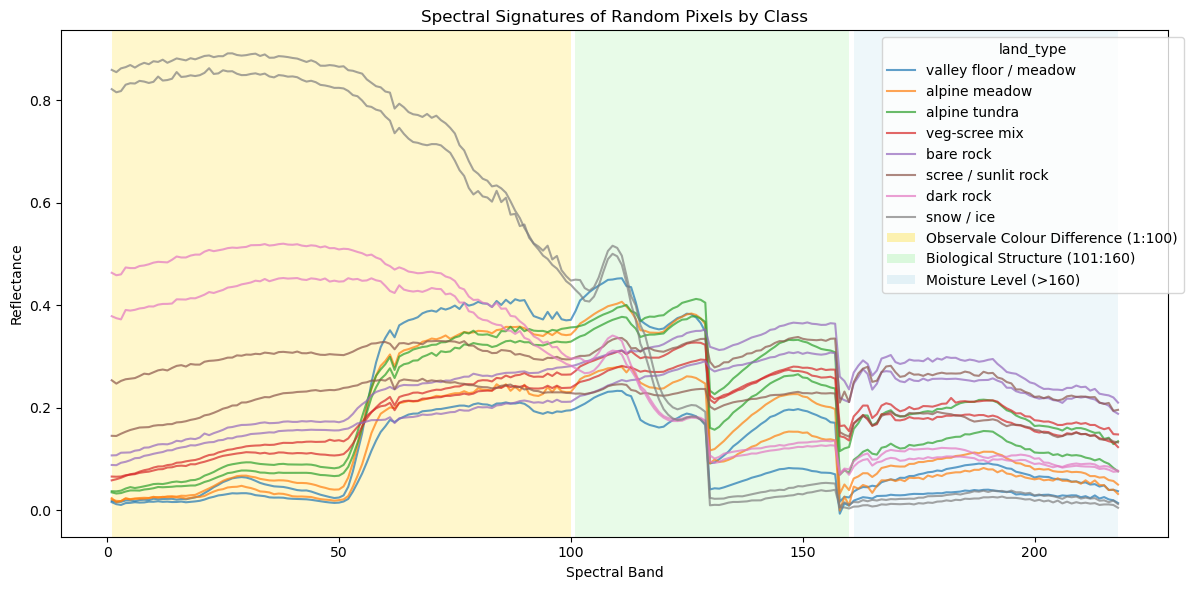

In [126]:
# plot spectral signatures of random pixels by class

bands = [c for c in base_df.columns if c.startswith("Band_")] # get band columns
classes = base_df['land_type'].unique() # get unique classes
palette = {cls: cm.get_cmap('tab10')(i % 10) for i, cls in enumerate(classes)} # assgn 10 distinct colours to classes

n_per_class = 2  # 2 pixels per class for consistency in visualization
plt.figure(figsize=(12, 6))

# loop over each class and randomly sample 2 pixels, without replacment
for cls in classes:
    idx_in_cls = base_df.index[base_df['land_type'] == cls]
    pick = np.random.choice(idx_in_cls, size=n_per_class, replace=False)

    # loop over each selectd pixel and get the bands
    for idx in pick:
        y = base_df.loc[idx, bands].values
        
        # plot the bands
        plt.plot(range(1, len(bands)+1), y, color=palette[cls], alpha=0.7,
                 label=f"{cls} (pixel {idx})")
        
# spectral bands regions
# 1 - 100: observable colour difference
obs_min, obs_max = 1, min(100, len(bands))
plt.axvspan(obs_min, obs_max, facecolor = 'gold', alpha = 0.2, label = "_nolegend_")

# 71 to 160: biological structure
bio_min, bio_max = 101, min(160, len(bands))
plt.axvspan(bio_min, bio_max, facecolor = 'lightgreen', alpha = 0.2, label = "_nolegend_")

# 151 to 218: moisture structure
if len(bands) > 160:
    moi_min, moi_max = 161, len(bands)
    plt.axvspan(moi_min, moi_max, facecolor = 'lightblue', alpha = 0.2, label = "_nolegend_")

# "prettifying" the legend to show only on entry pre class
handles, labels = plt.gca().get_legend_handles_labels()
first_of_class = {}
legend_handles = []
legend_labels  = []

# loop over and strip pixel's suffix off the label
for h, lab in zip(handles, labels):
    cls = lab.split(" (pixel")[0]

    # if it is the first time seeing the class then append to legend
    if cls not in first_of_class:
        first_of_class[cls] = True
        legend_handles.append(h)
        legend_labels.append(cls)

region_patches = [
    mpatches.Patch(facecolor = "gold", alpha = 0.3, label = "Observale Colour Difference (1:100)"),
    mpatches.Patch(facecolor = "lightgreen", alpha = 0.3, label = "Biological Structure (101:160)"),
    mpatches.Patch(facecolor = "lightblue", alpha = 0.3, label = "Moisture Level (>160)"),
]

legend_handles.extend(region_patches)
legend_labels.extend([
    "Observale Colour Difference (1:100)",
    "Biological Structure (101:160)",
    "Moisture Level (>160)"
])

# plot settings
plt.xlabel("Spectral Band") # Spectral band value (1 to 218 wavelengths) 
plt.ylabel("Reflectance") # Proportion fo incoming light reflected by the pixel at that particular band value. (higher=brighter)
plt.title("Spectral Signatures of Random Pixels by Class")
plt.legend(legend_handles, legend_labels, title="land_type", bbox_to_anchor=(1.02,1), loc="upper right")
plt.tight_layout()
plt.show()


-----
This plot of the spectral reflectance lines for each class supporting what was observed/described in the summary statistics above. 

-  From band_1 to band_100 (reflectance range sensitive to colour pigments), show great variation between classes. Land types such as snow and dark rock exhibits brighter colous which reflects visible light causing high reflectance. While meadows, tundras and veg-scree show less variation in visible reflectance bands due to their uniform surface colurs.

- Beyond band_100, the lines of each classes become smoother and more similar across classes. In these regions, light is no longer dominated by colour pigments but by biological structues and moisture, as seen from the plot mostly vegetations rich classes. Therefore, we see land types like meadows, tundras and veg-scree showing a higher reflectance band than snow and rock landscapes, as they have non-vegetated surfaces that lack internal structure.

----------

#### **b. EDA on Pixel Coordinates**

Understanding how each land type is spread out across the 355 by 608

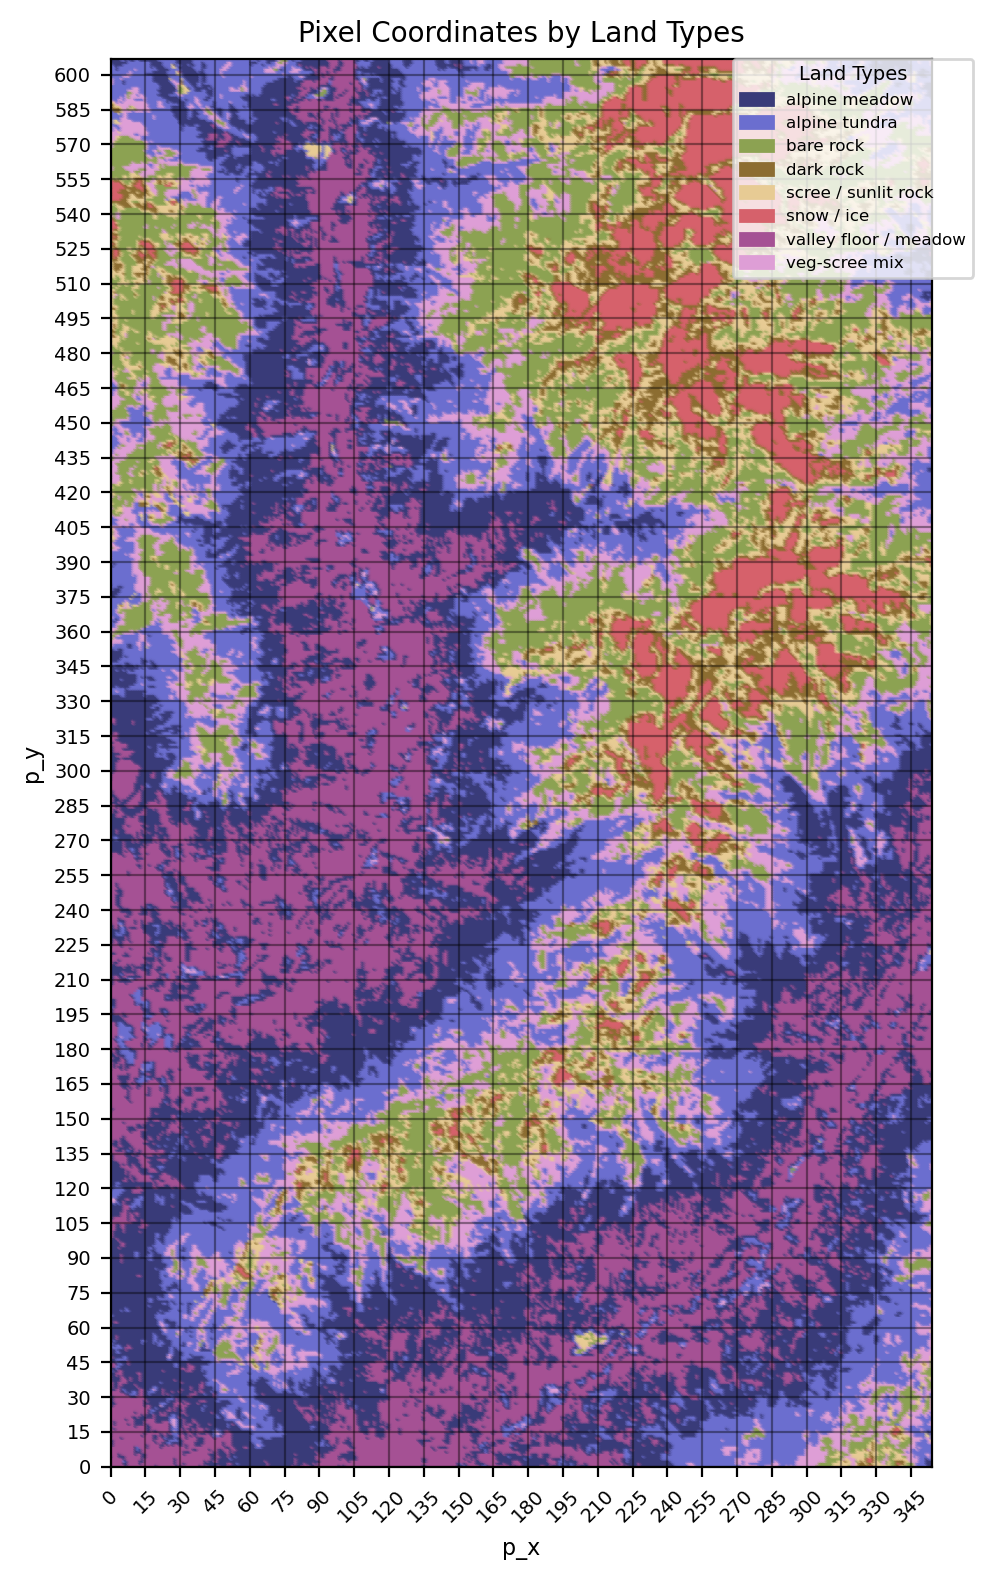

In [127]:
land_type_codes = base_df['land_type'].astype('category').cat.codes # convert category to numeric
land_type_categories = base_df['land_type'].astype('category').cat.categories # get unique categories

plt.figure(figsize=(5,8), dpi=200)  # roughly proportionate to 355/608

scatter = plt.scatter(
    base_df['p_x'], base_df['p_y'],
    c=land_type_codes,
    s=2,  
    alpha=0.5,
    cmap='tab20b'
)

# overlaying hard grid lines to visualise in patches
plt.xticks(np.arange(0, 355, 15))
plt.yticks(np.arange(0, 608, 15))
plt.grid(True, which='both', color='black', linestyle='-', linewidth=0.8, alpha=0.4)

# p_y increases from top to bottom in pd.df, while matplot lib's y-axis increases from bottom to top, there we need to invert the y-axis to match image coordinates
plt.gca().invert_yaxis() 
# 1 unit of p_x = 1 unit of p_y, specied to keep proportions otherwise matplot default will strecth out the plot
plt.gca().set_aspect('equal', adjustable='box') 


plt.title('Pixel Coordinates by Land Types', fontsize=10)
plt.xlabel('p_x', fontsize=8)
plt.ylabel('p_y', fontsize=8)
plt.xlim(0,354)
plt.ylim(0,607)

# create legend box
handles = [
    mpatches.Patch(color=scatter.cmap(scatter.norm(i)), # colour box matching scatter colours
                   label=land_type_categories[i])
    for i in range(len(land_type_categories)) # assign colours to each class
]
plt.legend(handles=handles,
            title="Land Types",
            bbox_to_anchor=(1.05, 1),
            loc='upper right',
            borderaxespad=0.,
            fontsize=6,
            title_fontsize=7
        )

# Simplify tick labels
plt.tick_params(labelsize=7)
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()


----------
If we were to break this plot into different small patches (shown in plot), we notice a strong spatial autocorrelation within the dataset, where nearby paired pixels usually share the same land type as they belong roughly to the same area. 

- A smaller distance from a reference pixel coordinates will share the same class as the reference pixel coordinate. 

- As distance from that reference pixel coordinate increase, the class will start to differ. 

--------

##### **Variogram of Pixel Coordinates**

To support what was observed, we take a 10000 random samples pixel pairs and measure how often they belong to the same class

/var/folders/kd/wns6rdkd2272l_snhv7bf6rw0000gn/T/ipykernel_62090/3876546703.py:17: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  variogram = dist_diff.groupby('bin')['diff'].mean() # comput average difference per bin


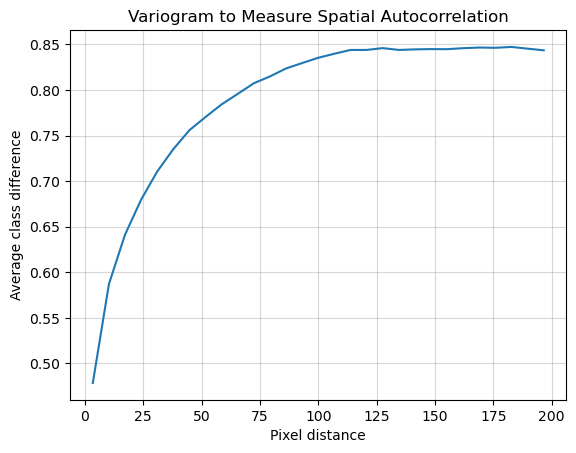

In [128]:
# get 10000 random samples to generate variagram
sample = base_df.sample(10000, random_state=101)

coords = sample[['p_x', 'p_y']].values
vals = sample['land_type'].astype('category').cat.codes.values

dist = pdist(coords) # euclidean distance between every pair of 10000 pixels

# get class differences, 0 if same, 1 if different
diff = pdist(vals.reshape(-1, 1), metric='hamming')

dist_diff = pd.DataFrame({'dist': dist, 'diff': diff})

# group by distance bins and calculate average class difference
dist_diff['bin'] = pd.cut(dist_diff['dist'], bins=np.linspace(0, 200, 30))

variogram = dist_diff.groupby('bin')['diff'].mean() # comput average difference per bin

plt.plot(variogram.index.categories.mid, variogram.values)

plt.xlabel("Pixel distance")
plt.ylabel("Average class difference")
plt.title("Variogram to Measure Spatial Autocorrelation")

plt.grid(True, linestyle = '-', alpha = 0.5)
plt.show();

-----
Plot confirms the existance of a strong spatial autocorrelation within the dataset. 

- At near 0 pixel distance, the average class difference is around 0.48, where 0 is the same and 1 is different, this value stands below 0.5 which is considerably low. 

    - Nearby pixels usually belong to the same class; make sense; as if i am in a meadow landscape and i walk 10 metres i will still be in a meadow landscape. 

    - Strong positive spatial autocorrelation.

- As pixel distance increases to 25 - 75, the pixels are less likely to share similar classes 
    - Decrease in correlation between data points

- Beyond 100 pixel distance, the pixel classes are no longer correlated as the line flattens out and data points exhibit random behaviour.

Due to spatial auto correlation, when doing a random train/test split. Some pixels that exist in the same patch will end up being in both train and test set. 

Under our observation that pixels from the same patch will share the same characteristics, our classification model would have essentially 'seen' the same patch twice and give unrealistically high accuracy. But when applying to unseen regions, the performance will drop as the model does not generalise well.
- <span style="color:red"> Note: Use spatial train/test split by splitting dataset by blocks

---------

#### **c. EDA on Colour Codes**

In [129]:
# uniqueness check 
#log(f'Unique RGB colours: {base_df['rgb_hex'].nunique()}', 'info')
#log(f'Unique overlay colours: {base_df['overlay_hex'].nunique()}', 'info')

##### **i. Understanding 'rgb_hex'**

Research context: e.g. #030B05 rgb_hex values are written in #RRGGBB. With 00 = not intense at all and FF = very intense.
- Therefore, the rgb_hex value above represents, Red = 03, Green = 0B, Blue = 05 (Green being the most dominating colour pigment)

- We can split the string of rgb_hex values up to R, G and B and then check correlation of them to the spectral reflectance

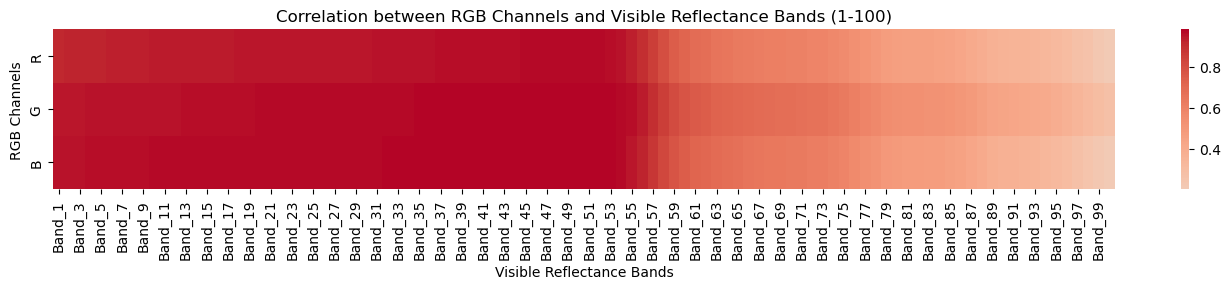

In [130]:
# extract RGB columns
base_df[['R','G','B']] = base_df['rgb_hex'].apply(
    lambda x: pd.Series([int(x[i:i+2], 16) for i in (1,3,5)])
)

# compare against all the visible bands
visible_bands = [f'Band_{i}' for i in range(1, 101)]
corr_matrix = base_df[['R', 'G', 'B'] + visible_bands].corr().loc[['R','G','B'], visible_bands] # compute correlation matrix

# plot corr heatmap
plt.figure(figsize=(14, 3))

sns.heatmap(
    corr_matrix,
    cmap='coolwarm',
    center=0
)

plt.title("Correlation between RGB Channels and Visible Reflectance Bands (1-100)")
plt.xlabel("Visible Reflectance Bands")
plt.ylabel("RGB Channels")
plt.tight_layout()
plt.show()

# drop R, G, B columns after analysis
base_df.drop(columns=['R','G','B'], inplace=True)

------
The correlation plot shows that the RGB channel values (rgb_hex) are very strongly correlated with the visible reflectance bands; particularly up to band_77. 

- Suggesting the rgb_hex values could likely be derived from these visible bands, as it correspond to the portion of the spectrum that is most influenced by colour pigments.

- While slightly more than half (band_1 to band_60) displaying a correlation value of 1, the rgb_hex values appear to encode the visible component of the reflectance value.

-------

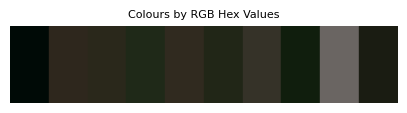

In [131]:
# viewing the actual colours of the rgb_hex values
sample_colors = base_df['rgb_hex'].sample(10, random_state=101) # randomly select 10

fig, ax = plt.subplots(figsize=(5,1), dpi = 100)

# loop through each rgb_hex and plot the coloured rectangles
for i, color in enumerate(sample_colors):
    ax.add_patch(
        mpatches.Rectangle((i,0), 1, 1, color=color) # plot in 1x1 and place each new rectangle beside the prev
        )
    
plt.title("Colours by RGB Hex Values", fontsize=8)
ax.set_xlim(0,10)
ax.set_ylim(0,1)
ax.axis('off')
plt.show()

-----
Plotting the rgb_hex colours of 10 randomly select value allow us to satisfy the assumption from our EDA that that the rgb_hex values are likely derived from the visible reflectance bands that prioritise colour pigments.

<span style="color:red"> Note: This raises mulitcollinearity issues with our dataset. I suggest dropping this column for certain models that are prone to overfitting.

------


##### **ii. Understanding 'overlay_hex'**

'overlay_hex' only has 8 unique values among all the dataset, at the same time we have 8 unique classes within the dataset as well. 'overlay_hex' values could possibly be used as a representative baseline colour for each class.

In [132]:
# check if each land_type has a unique overlay_hex
base_df.groupby('land_type')['overlay_hex'].nunique()

land_type
alpine meadow            1
alpine tundra            1
bare rock                1
dark rock                1
scree / sunlit rock      1
snow / ice               1
valley floor / meadow    1
veg-scree mix            1
Name: overlay_hex, dtype: int64

----------
Each class indeed has it's own unique overlay_hex value

To further visualise/understand the overlay_hex value, we can plot the pixel coordinates just like what has done above but instead of assigning a random colour to each class, we use the overlay_hex value to colour the pixels without bringing in the classes

------

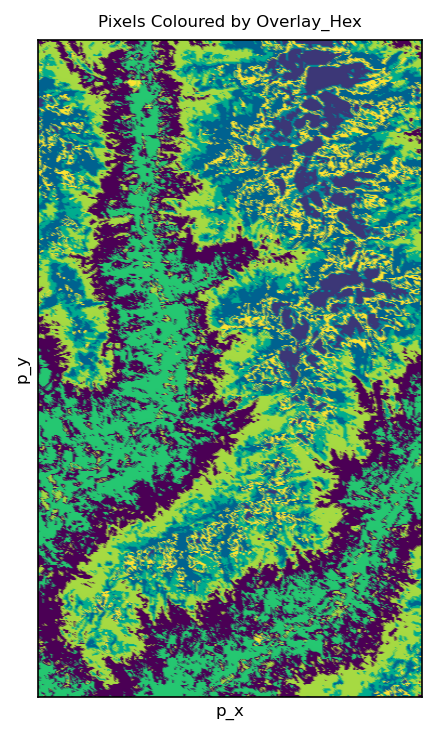

In [133]:
plt.figure(figsize=(3, 5), dpi=150)

# scatter plot using overlay_hex values
plt.scatter(
    base_df['p_x'], base_df['p_y'],
    c=base_df['overlay_hex'], # use overlay_hex for colours
    s=2,
    alpha=0.8
)

# p_y increases from top to bottom, while matplot lib's y-axis increases from bottom to top, there we need to invert the y-axis to match image coordinates
plt.gca().invert_yaxis() 
# 1 unit of p_x = 1 unit of p_y, specied to keep proportions otherwise matplot default will strecth out the plot
plt.gca().set_aspect('equal', adjustable='box') 


plt.title('Pixels Coloured by Overlay_Hex', fontsize=8)
plt.xlabel('p_x', fontsize=8)
plt.ylabel('p_y', fontsize=8)
plt.xlim(0, 354)
plt.ylim(0, 607)

# remove tick labels for cleaner look
plt.tick_params(
    labelbottom =False,
    labelleft =False,
    bottom=False,
    left=False
)

plt.tight_layout()
plt.show()

-------
The 'overlay_hex' values are perfectly correlated with the land type classes. 

- Plot above matches almost identically when we were doing the EDA of pixel coordinates when we assign a random colour to each class.

<span style="color:red"> Note: Since, we are classifying land types, I strongly suggest overlay_hex column to be dropped, as our classification model could/definitely memorise these mapping between overlay_hex values to land type and not learn anything from spectral data.

---------

#### **d. EDA on Land Types (Target)**
If a single class dominates, the classification model can get high overall accuracy by always predicting the majority class

In [134]:
# count each class occurences
class_counts = base_df['land_type'].value_counts()
log(f'Class Distribution:\n{class_counts}', "info")

# imbalance checks
majority = class_counts.iloc[0] # get the highest count
minority = class_counts.iloc[-1]# get the lowest count

imbalance_ratio = majority / minority if minority > 0 else float('inf')
log(f'Imbalance Ratio (majority/minority): \n{imbalance_ratio}', "info")


[INFO] - Class Distribution:
land_type
alpine meadow            50657
alpine tundra            38900
valley floor / meadow    38424
bare rock                26314
veg-scree mix            24495
scree / sunlit rock      15153
snow / ice               11533
dark rock                10128
Name: count, dtype: int64
[INFO] - Imbalance Ratio (majority/minority): 
5.001678515007899


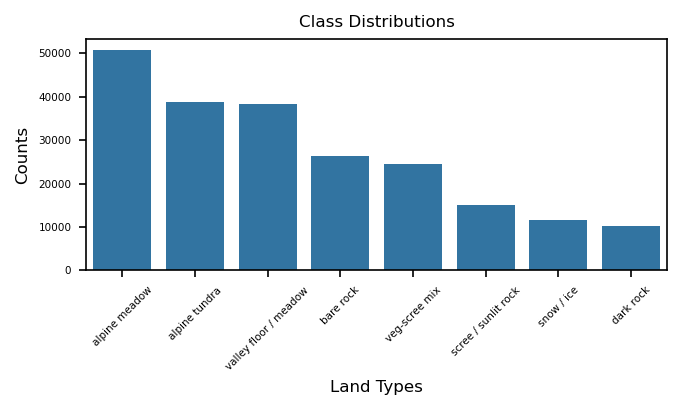

In [135]:
plt.figure(figsize=(5, 2), dpi = 150)
sns.barplot(
    x=class_counts.index,
    y=class_counts.values
)

plt.title('Class Distributions', fontsize=8)
plt.xlabel('Land Types', fontsize=8)
plt.ylabel('Counts', fontsize=8 )
plt.tick_params(labelsize=5)
plt.xticks(rotation=45)
plt.show()

---------
There is a slight to moderate class imbalance within the dataset provided. As mentioned earlier, this could affect our models especially when we are doing classification models for this tasks. While the model we train can still learn, it may learn to favour 'alpine meadow' which is the majority class and performs poorly on low occurance classes like 'dark rock'.

---------

#### **e. EDA on Features Interaction with Land Types**

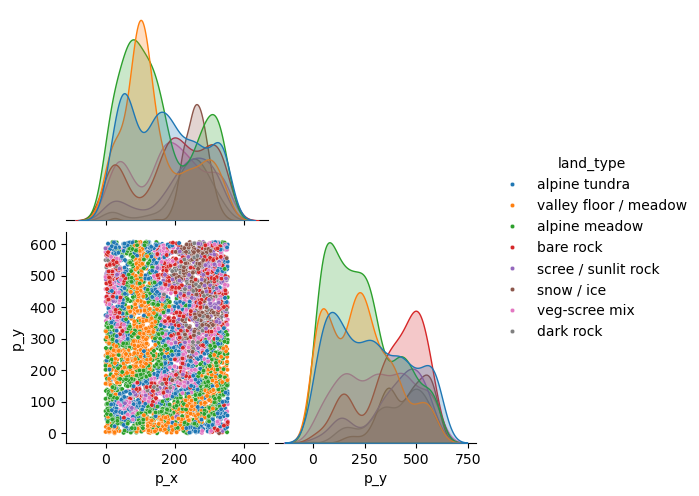

In [136]:
# pair plot for pixel coordinates
pixels = ['p_x', 'p_y']
sns.pairplot(base_df.sample(5000),
             vars = pixels,
             hue = 'land_type',
             plot_kws={'s': 10, 'alpha':1},
             corner=True
             )

------
Pixel coordinates do not distinctly seperate the different land types as their distribution overlaps. However pixel coordinates provide good spatial context to complement spectral band features.

------

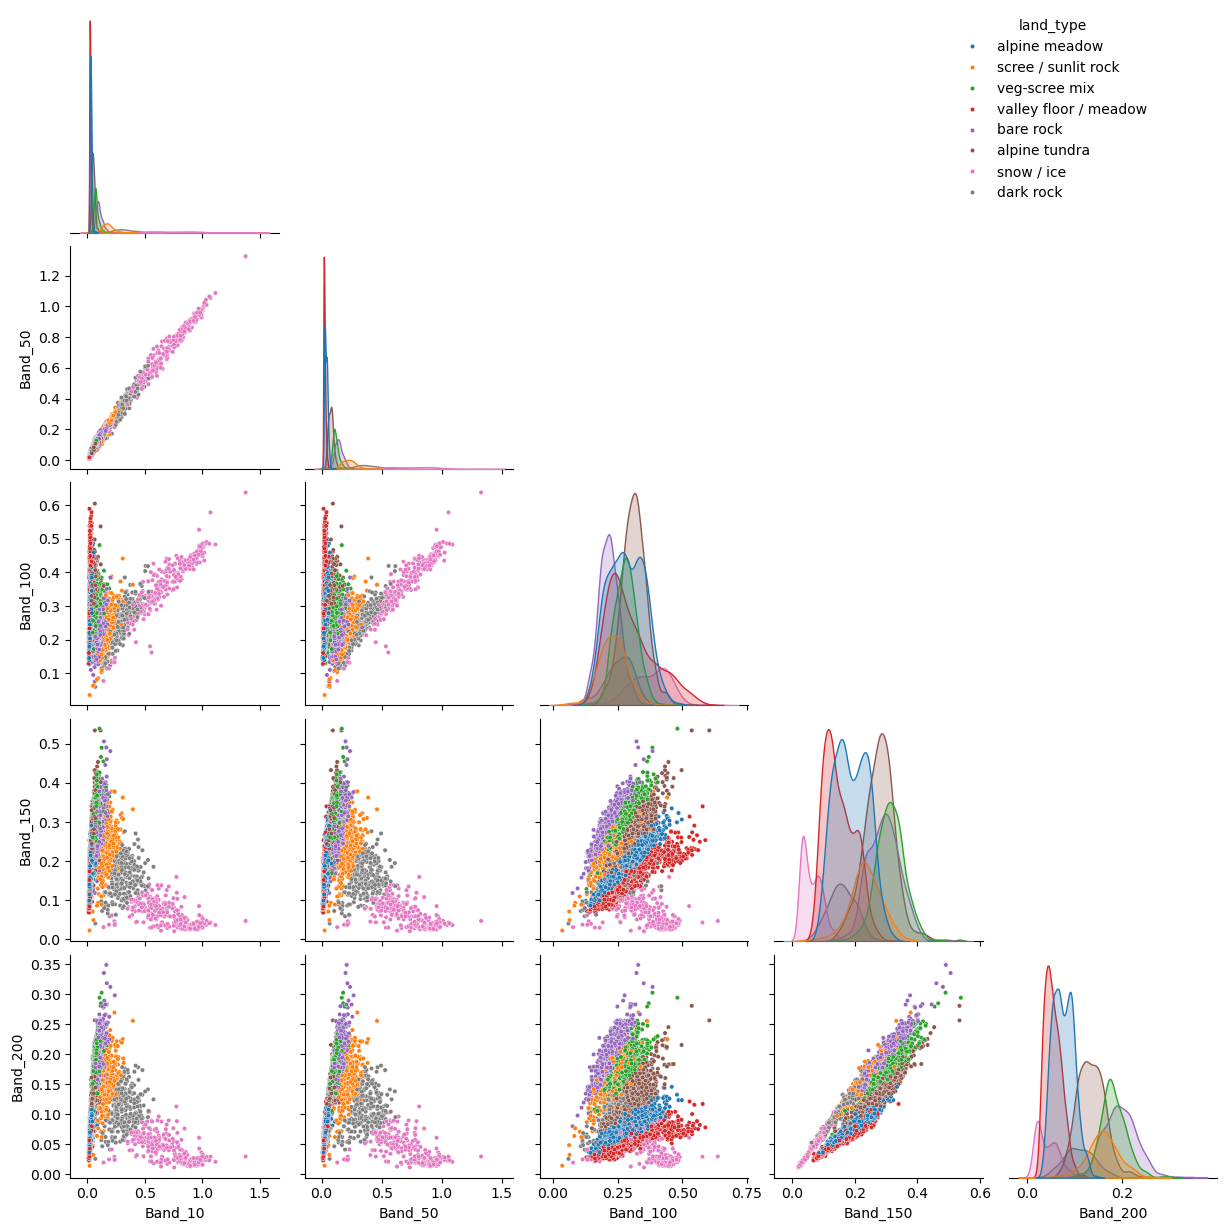

In [137]:
# pair plot for spectral bands
# unable to choose all 218 bands, so only selected a few
bands = ['Band_10', 'Band_50', 'Band_100', 'Band_150', 'Band_200']

# pair plot
g = sns.pairplot(base_df.sample(5000),
             vars = bands,
             hue = 'land_type',
             plot_kws={'s': 10, 'alpha':1},
             corner=True
             )

g._legend.set_bbox_to_anchor((0.80, 0.98))
g._legend.set_loc('upper right')

plt.show()

-------
There are distinct seperations between classes such as snow and dark rock, as these land types occupy unique regions within the reflectance space. However, classes such as meadows and tundras share similar spectral behaviour due to similar dense vegetation properties. 

Including the pixel cooridnates among the input features will allow the classification models to learn spatial patterns which complements the spectral information, improving the distinction between these spectrally similar classes.

----------


## **2. Feature Engineering**

-----

#### **a. Drop 'rgb_hex' and 'overlay_hex'**
As shown in the EDA above, 
- 'rgb_hex' values caused multicollinearity within the features
- 'overlay_hex' values are perfectly correlated with the target, causing data leakage issues

We will be dropping these column from our input features to our classification models

In [138]:
# drop 'rgb_hex' and 'overlay_hex' columns as they are not useful for modelling
df = base_df.drop(columns=['rgb_hex', 'overlay_hex'])
display(df.head())

,land_type,p_x,p_y,Band_1,Band_2,Band_3,Band_4,Band_5,Band_6,Band_7,...,Band_209,Band_210,Band_211,Band_212,Band_213,Band_214,Band_215,Band_216,Band_217,Band_218
0,valley floor / meadow,0,0,0.0174,0.0131,0.0108,0.0133,0.0158,0.0144,0.0151,...,0.0274,0.0269,0.0237,0.0231,0.0224,0.0246,0.0255,0.0174,0.0234,0.0147
1,valley floor / meadow,1,0,0.0180,0.0124,0.0116,0.0143,0.0154,0.0136,0.0151,...,0.0350,0.0247,0.0289,0.0275,0.0288,0.0293,0.0286,0.0211,0.0229,0.0176
2,valley floor / meadow,2,0,0.0151,0.0150,0.0113,0.0158,0.0167,0.0158,0.0163,...,0.0401,0.0326,0.0358,0.0319,0.0355,0.0274,0.0303,0.0232,0.0282,0.0181
3,valley floor / meadow,3,0,0.0172,0.0149,0.0095,0.0156,0.0154,0.0169,0.0176,...,0.0365,0.0306,0.0310,0.0294,0.0307,0.0238,0.0304,0.0232,0.0247,0.0087
4,valley floor / meadow,4,0,0.0184,0.0149,0.0143,0.0189,0.0174,0.0174,0.0182,...,0.0443,0.0450,0.0428,0.0372,0.0407,0.0344,0.0415,0.0287,0.0317,0.0176


#### **b. Handling High Correlations Between Reflectance Bands**

- With 218 bands, majority of the bands might be highly correlated


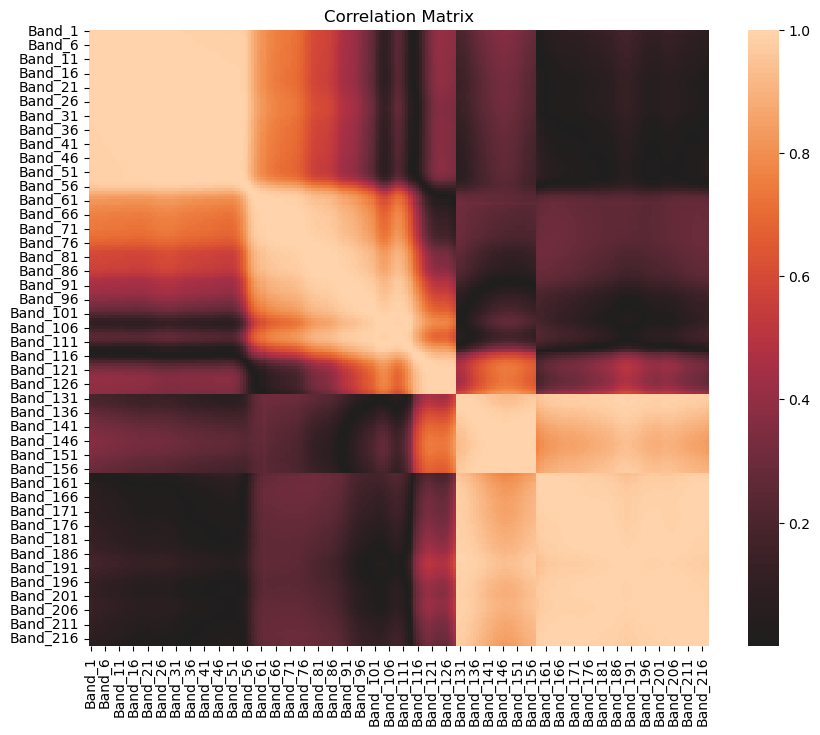

In [139]:
# get all reflectance bands column
bands_only = df.drop(columns = ['land_type', 'p_x', 'p_y'])
band_names = bands_only.columns

# get corr matrix
bcorr_matrix = bands_only[band_names].corr().abs()

# check for correlations between bands
plt.figure(figsize=(10, 8))
sns.heatmap(bcorr_matrix, 
            center=0,
)
plt.title("Correlation Matrix")
plt.show()

------
The correlation heatmap shows four clusters of higher correlated reflectance bands. 

- Band 1-56
- Band 57-112
- Band 113-157
- Band 158-218

Each of these groups contains bands that are strongly correlated but are weakly correlated with other groups.

While we can:
1. Group them up and average out the four features 
2. Pick a few bands to represent each clusters

Both of these methods put us in a trade-off scenario where we are losing possibly quite a bit of information at the chance of not encountering multicollinearity issues. 

Alternatively, we can perform correlation based hierarchical clustering approach where we use the correlation matrix to group highly correlated bands together and pick one form each group instead of using the manual approach above.

------

##### **i. Hierarchical Correlation Clustering**

[INFO] - Number of clusters formed: 8
[INFO] - Selected bands after clustering:
Band_1
Band_57
Band_60
Band_101
Band_80
Band_115
Band_135
Band_130


,land_type,p_x,p_y,Band_1,Band_57,Band_60,Band_80,Band_101,Band_115,Band_130,Band_135
0,valley floor / meadow,0,0,0.0174,0.1309,0.1897,0.237833,0.214333,0.1943,0.0411,0.0503
1,valley floor / meadow,1,0,0.0180,0.1232,0.1764,0.227167,0.211433,0.1993,0.0493,0.0581
2,valley floor / meadow,2,0,0.0151,0.1422,0.2028,0.262333,0.251300,0.2420,0.0574,0.0735
3,valley floor / meadow,3,0,0.0172,0.1625,0.2328,0.291300,0.273867,0.2543,0.0569,0.0714
4,valley floor / meadow,4,0,0.0184,0.1752,0.2482,0.301933,0.282667,0.2601,0.0687,0.0844


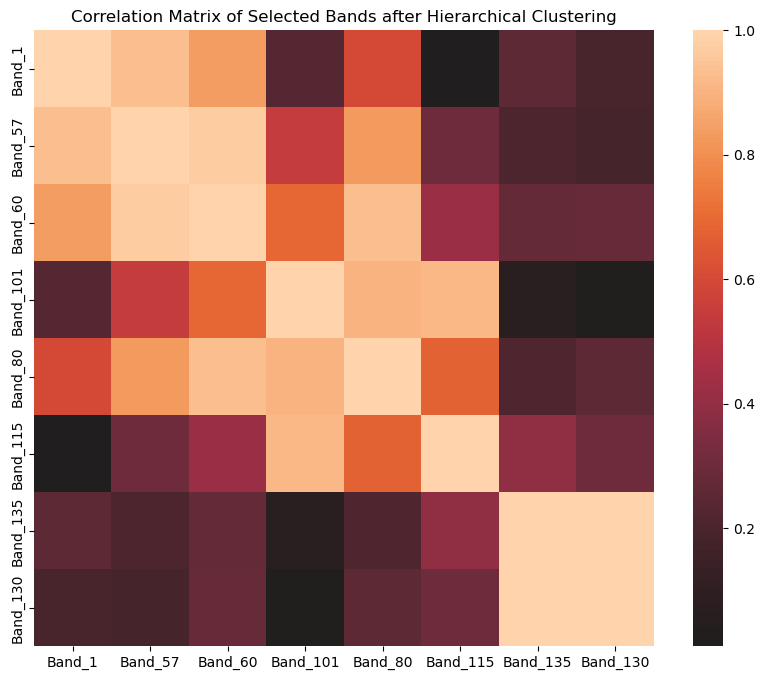

In [140]:
# compute the correlation distance
corr_dist = 1 - bcorr_matrix # 0 = identical, 0.2 = quite different
sq_formcorr = squareform(corr_dist, checks=False) # convert square matrix to condensed distance format

# Using hierarchical clustering we group similar bands together based on their distances
linkagem = linkage(sq_formcorr, method='average')

# given a threshold of 95% correlation we group bands by <= 0.05 distance
max_dist = 0.05 # cut at 0.05 distance to form clusters
cluster_labs = fcluster(linkagem, t=max_dist, criterion = 'distance');

# assign each band to their clusters
cluster = pd.DataFrame({'band':band_names, 'cluster':cluster_labs})
log(f'Number of clusters formed: {cluster["cluster"].nunique()}', 'info')

# select one band per class
selected_bands = cluster.groupby('cluster')['band'].first().tolist()

log('Selected bands after clustering:', 'info')
for bands in selected_bands:
    print(bands)

# drop all unselected bands from dataframe 
df_clustered = df.drop(columns=[c for c in band_names if c not in selected_bands])
display(df_clustered.head())

# replot correlation matrix
new_bands = df_clustered.drop(columns = ['land_type', 'p_x', 'p_y'])
bcorr_matrix = new_bands[selected_bands].corr().abs()

# check for correlations between bands
plt.figure(figsize=(10, 8))
sns.heatmap(bcorr_matrix, 
            center=0
            )
plt.title("Correlation Matrix of Selected Bands after Hierarchical Clustering")
plt.show()

##### **ii. Manually Selecting 1 Representative Per Correlation Group**

[INFO] - Manually selected bands:
Band_29
Band_85
Band_136
Band_188


,land_type,p_x,p_y,Band_29,Band_85,Band_136,Band_188
0,valley floor / meadow,0,0,0.0365,0.233533,0.0535,0.0376
1,valley floor / meadow,1,0,0.0360,0.225233,0.0617,0.0440
2,valley floor / meadow,2,0,0.0410,0.257733,0.0769,0.0548
3,valley floor / meadow,3,0,0.0456,0.288300,0.0759,0.0517
4,valley floor / meadow,4,0,0.0498,0.301467,0.0894,0.0669


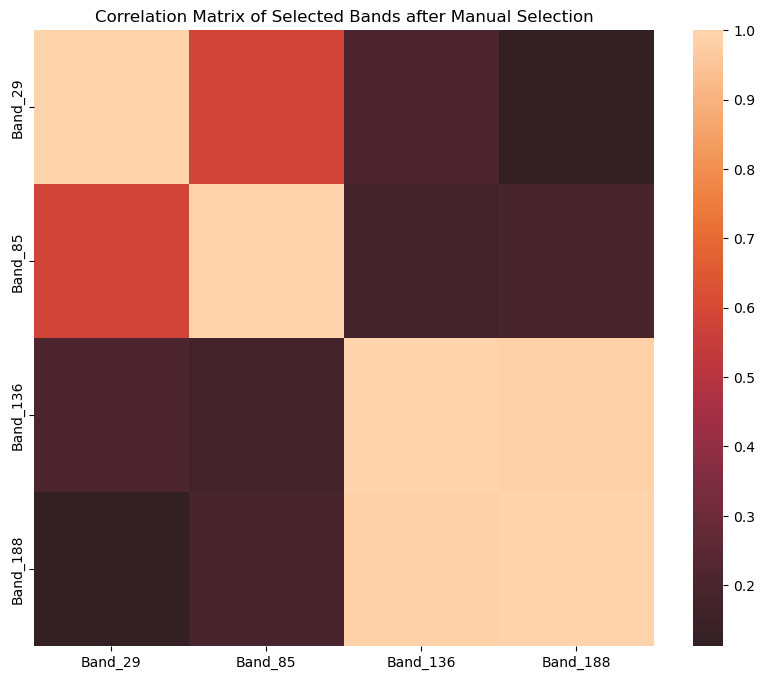

In [141]:
# define band groupings 
group1 = [f'Band_{i}' for i in range(1, 57)]      # Bands 1-56
group2 = [f'Band_{i}' for i in range(57, 114)]    # Bands 57-113
group3 = [f'Band_{i}' for i in range(114, 158)]   # Bands 114-157
group4 = [f'Band_{i}' for i in range(158, 219)]   # Bands 158-218

# choose the median band from each group as representative
m_selected_bands = [group1[len(group1)//2],
                    group2[len(group2)//2],
                    group3[len(group3)//2],
                    group4[len(group4)//2]
                ]

log('Manually selected bands:', 'info')
for bands in m_selected_bands:
    print(bands)

df_manual = df.drop(columns=[c for c in band_names if c not in m_selected_bands])
display(df_manual.head())

# replot correlation matrix
new_bandsm = df_manual.drop(columns = ['land_type', 'p_x', 'p_y'])
bcorr_matrix = new_bandsm[m_selected_bands].corr().abs()

# check for correlations between bands
plt.figure(figsize=(10, 8))
sns.heatmap(bcorr_matrix, center=0)
plt.title("Correlation Matrix of Selected Bands after Manual Selection")
plt.show()

-----------
We now have 2 dataframes:

1. df_cluster 

- Created using hierarchical clustering on the full correlation matrix to automatically identify groups of highly correlated bands then select 1 band for each cluster
    - This approach allowed us to balance out the trade off between retaining underlying information within our dataset and reducing multicollinearity issues within band features

2. df_manual

- Created manually by dividing the spectral bands into 4 wavelength ranges by looking at the correlation matrix and selecting the median band as the representative band
    - This approach effectively reduce the multicollinerity but at the same time it risk discarding significant amount of information within the dataset.

While manual approach (df_manual) is a intuitively simple and easy, the correlation plot still indicates multicollinearity not being fully eliminated and valuable information may be lost.

We prefered to proceed with the hierarchical cluster (df_cluster) approach for model building as it provides a clear balance solution to the minimising of multicollinearity while preserving information of the features. The remaining correlations are expected, due to smooth nature of continuous reflectane spectra bands. 

--------


## **3. Data Split/Preparation**
-----------

#### **a. Train Test Split**

Due to spatial autocorrelation, we decided to proceed with an approach of splitting the satelite image up into 16 different sections using the pixel coordinates (p_x, p_y) and use 3 portions for test and the 14 other corners for training. This will prevent data leakage as explained earlier in the EDA portion.

In [142]:
# function to create blocks 
def create_blocks (df):
    x_col = 'p_x'
    y_col = 'p_y'
    n_blockX = 4
    n_blockY = 4
    prefix = 'block'

    output_df = df.copy()

    # create block indices along X and Y 
    output_df[f'{prefix}_x'] = pd.cut(output_df[x_col], bins=n_blockX, labels=False)
    output_df[f'{prefix}_y'] = pd.cut(output_df[y_col], bins=n_blockY, labels=False)

    # combine them to create blockIds
    output_df[f'{prefix}_id'] = output_df[f'{prefix}_x'].astype(str) + '_' + output_df[f'{prefix}_y'].astype(str)

    unique_blocks = output_df[f'{prefix}_id'].unique()
    log(f'Unique blocks created: {unique_blocks}', 'info')

    return output_df, unique_blocks

In [143]:
bcluster_df, unique_blocks = create_blocks(df_clustered)

[INFO] - Unique blocks created: ['0_0' '1_0' '2_0' '3_0' '0_1' '1_1' '2_1' '3_1' '0_2' '1_2' '2_2' '3_2'
 '0_3' '1_3' '2_3' '3_3']


/var/folders/kd/wns6rdkd2272l_snhv7bf6rw0000gn/T/ipykernel_62090/2843099817.py:15: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed two minor releases later. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap(obj)`` instead.
  block_colours = plt.cm.get_cmap('viridis', len(unique_blocks))


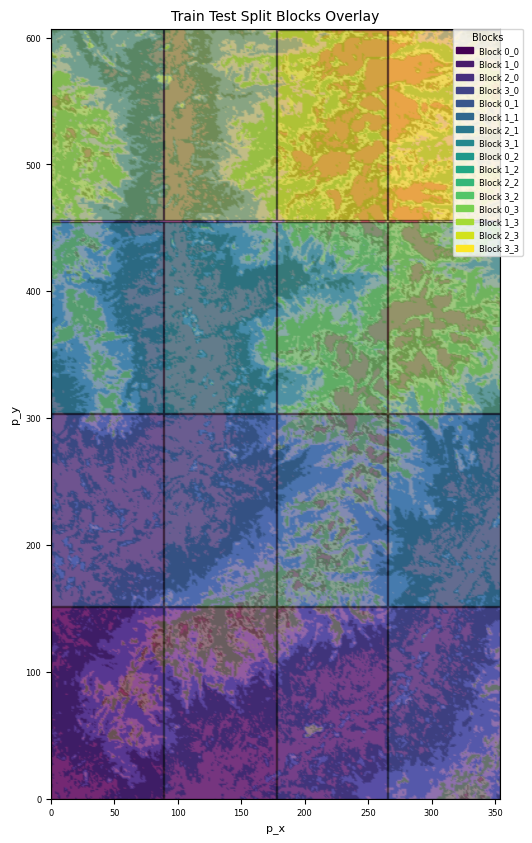

In [144]:
# visualise to look at the spatial blocks created

plt.figure(figsize=(7,10), dpi=100)  # roughly proportionate to 355/608
# plot for land types
plt.scatter(
        bcluster_df['p_x'], bcluster_df['p_y'],
        c=land_type_codes,
        s=2,
        alpha=0.5,
        cmap='tab20b'
    )

# overlaying the created blocks
# assign colours to each block
block_colours = plt.cm.get_cmap('viridis', len(unique_blocks))
 
for i, block in enumerate(unique_blocks):
    block_data = bcluster_df[bcluster_df['block_id'] == block]
    x_min, x_max = block_data['p_x'].min(), block_data['p_x'].max()
    y_min, y_max = block_data['p_y'].min(), block_data['p_y'].max()

    # plot rectangles for each blocks
    rect = mpatches.Rectangle((x_min, y_min),
                                x_max - x_min,
                                y_max - y_min,
                                linewidth=1,
                                edgecolor='black',
                                facecolor=block_colours(i),
                                alpha = 0.5, 
                                label = f'Block {block}'
                            )
    plt.gca().add_patch(rect)

plt.gca().invert_yaxis()
plt.gca().set_aspect('equal', adjustable='box')

plt.title('Train Test Split Blocks Overlay', fontsize=10)
plt.xlabel('p_x', fontsize=8)
plt.ylabel('p_y', fontsize=8) 
plt.xlim(0,354)
plt.ylim(0,607) 

# legend for blocks
handles = [
    mpatches.Patch(color=block_colours(i), 
                   alpha = 1.0, 
                   label=f'Block {b}')
    for i, b in enumerate(unique_blocks)
]

plt.legend(
    handles=handles,
    title="Blocks",
    bbox_to_anchor=(1.05, 1),
    loc='upper right',
    borderaxespad=0.,
    fontsize=6,
    title_fontsize=7
)
plt.tick_params(labelsize = 6)

plt.show()


-------
We will choose 'Block 2_1', 'Block '3_0' and 'Block 0_2' as the test data and the rest as the training data

-------

In [145]:
test_blocks = ['2_1', '3_0', '0_2'] # test block_ids
test_df = bcluster_df[bcluster_df['block_id'].isin(test_blocks)] # test data
train_df = bcluster_df[~bcluster_df['block_id'].isin(test_blocks)] # train data

X_train = train_df.drop(columns=['land_type', 'block_x', 'block_y', 'block_id'])

X_test = test_df.drop(columns=['land_type', 'block_x', 'block_y', 'block_id'])



#### **b. Repeat for PCA**

- Split to spatial blocks using the full dataframe (Without Hierarchical Clustered)

In [146]:
# partition rows by their spatial blocks
pca_df, unique_blocks = create_blocks(df)

# split train and test
# test blocks are 2_1, 3_0 and 0_2
test_pcadf = pca_df[pca_df['block_id'].isin(test_blocks)]
train_pcadf = pca_df[~pca_df['block_id'].isin(test_blocks)]

pcaX_train = train_pcadf.drop(columns=['land_type', 'block_x', 'block_y', 'block_id'])
pcaX_test = test_pcadf.drop(columns=['land_type', 'block_x', 'block_y', 'block_id'])


[INFO] - Unique blocks created: ['0_0' '1_0' '2_0' '3_0' '0_1' '1_1' '2_1' '3_1' '0_2' '1_2' '2_2' '3_2'
 '0_3' '1_3' '2_3' '3_3']


**i. Perform PCA on X features** 
- For results analysis

In [147]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(pcaX_train)
X_test_scled = scaler.transform(pcaX_test)

pca = PCA(n_components = 10)
X_train_pca = pca.fit_transform(X_train_scaled)
X_test_pca = pca.transform(X_test_scled)

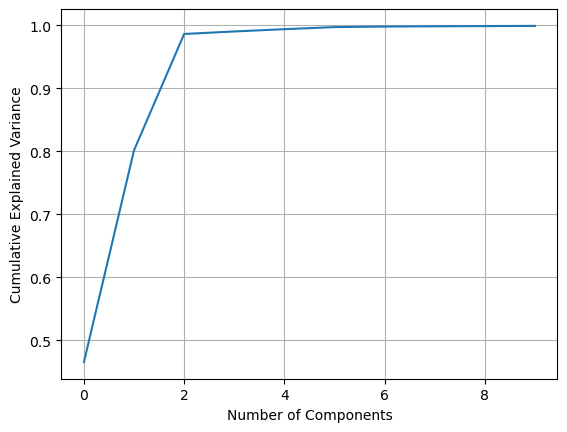

In [148]:
# visualisation
plt.plot(np.cumsum(pca.explained_variance_ratio_))
plt.xlabel('Number of Components')
plt.ylabel('Cumulative Explained Variance')
plt.grid(True)
plt.show()

First few components explain most of the variance with each components added, a lot of new information is provided. After the 4th component, each added component adds very little information. Therefore, we analysed at 4 compoenents is a good cut off point, providing 98% of the variance explained in the data.

-----------

#### **c. Encoding for Land Types**

In [149]:
# create label encoder instance
l_e = LabelEncoder()

# encoding land_type labels
y_train = l_e.fit_transform(train_df['land_type'])
y_test = l_e.transform(test_df['land_type'])

log('Encoded land_type labels mapping:', 'info')
dict(zip(l_e.classes_, range(len(l_e.classes_)))) # view mapping of classes to encoded labels

[INFO] - Encoded land_type labels mapping:


{'alpine meadow': 0,
 'alpine tundra': 1,
 'bare rock': 2,
 'dark rock': 3,
 'scree / sunlit rock': 4,
 'snow / ice': 5,
 'valley floor / meadow': 6,
 'veg-scree mix': 7}

In [150]:
# data distribution checks 
# NOTE: please turn out scrollable element to view full output

log('Printing data distribution checks:', 'info')

print(f'\n-----------------------------------')

# blocks assinged
print(f"\nTrain block IDs:", train_df['block_id'].unique())
print(f"Test block IDs:", test_df['block_id'].unique())
print(f'-----------------------------------')

# row counts 
print(f"\nNumber of training samples: {len(train_df):,}")
print(f"Number of testing samples:  {len(test_df):,}")

print(f'-----------------------------------')

# class distributions in train and test sets
print("\nTrain class distribution:")
print(train_df['land_type'].value_counts())

print("\nTest class distribution:")
print(test_df['land_type'].value_counts())
print(f'-----------------------------------')


[INFO] - Printing data distribution checks:

-----------------------------------

Train block IDs: ['0_0' '1_0' '2_0' '0_1' '1_1' '3_1' '1_2' '2_2' '3_2' '0_3' '1_3' '2_3'
 '3_3']
Test block IDs: ['3_0' '2_1' '0_2']
-----------------------------------

Number of training samples: 175,172
Number of testing samples:  40,432
-----------------------------------

Train class distribution:
land_type
alpine meadow            41277
valley floor / meadow    34164
alpine tundra            28229
bare rock                21675
veg-scree mix            17294
scree / sunlit rock      12773
snow / ice               10884
dark rock                 8876
Name: count, dtype: int64

Test class distribution:
land_type
alpine tundra            10671
alpine meadow             9380
veg-scree mix             7201
bare rock                 4639
valley floor / meadow     4260
scree / sunlit rock       2380
dark rock                 1252
snow / ice                 649
Name: count, dtype: int64
-------------------

## **4. Classification Modeling**

------

In [151]:
# function for cross validation training
def train_cv (X_train, y_train, model_info, groups = train_df['block_id'], scale=False, use_pca=False, pca_ncomp=None):
    
    model = model_info['model'] # extract model name
    param_grid = model_info['parameters'] # extract parameters for tuning
    steps = []

    # scale toggling function; perform scaling if scale = True
    if scale == True:
        log(f'Applying scaling for model: {model}', 'warning')
        # pipeline = Pipeline([
        #     ('Scalar', StandardScaler()),
        #     ('Model', model)
        # ])
        steps.append(('Scaler', StandardScaler()))
        
    else:
        log(f'Scaling is turned off: Scale = {scale}, for {model}', 'warning')
        # pipeline = Pipeline([
        #     ('Model', model)
        # ])
    
    # pca toggling config
    if use_pca == True:
        log('PCA is enabled', 'info')
        steps.append(('PCA', PCA(n_components = pca_ncomp)))

    else:
        log('PCA is toggled off', 'info')

    steps.append(('Model', model))
    pipeline = Pipeline(steps)

    # group 5 fold cross validation
    gkf = GroupKFold(n_splits=5)

    CV = GridSearchCV(estimator = pipeline,  
                    param_grid = param_grid,                # test all parameters
                    cv = gkf,                               # evaluate each fold based on the block_ids
                    n_jobs = -1,                            # processing configurations
                    scoring = 'balanced_accuracy',          # handle the class imbalance
                    verbose = 1                             # show progress
                    )

    CV.fit(X_train, y_train, groups = groups)

    best_model = CV.best_estimator_
    best_params = CV.best_params_
    best_score = CV.best_score_
    gridscv_fit = CV

    log(f'Best parameters: {best_params}', 'info')
    log(f'Best CV balance score: {best_score:.4f}', 'info')

    return best_model, best_params, best_score, gridscv_fit

In [152]:
def test (model_name, model_fit, X_test, y_test):

    # # predictions
    # if default == True & scale == True:
    #     scaler = StandardScaler()
    #     X_test_scaled = scaler.fit_transform(X_test)
        
    # else: 
    #     X_test_scaled = X_test

    # dynamically handle xgboost model type
    if isinstance(model_fit, xgb.Booster):
        
        # for XGBoost
        dtest = xgb.DMatrix(X_test)
        ntrees = int(model_fit.attributes().get('best_iteration', 200))
        y_pred_proba = model_fit.predict(dtest, iteration_range = (0, ntrees))
        y_pred = np.argmax(y_pred_proba, axis =1)

    else:
        # regular sklearn model type
        y_pred = model_fit.predict(X_test)


    # confusion matrix
    conf_matrix = confusion_matrix(y_test, y_pred)

    # plot confusion matrix 
    plt.figure(figsize = (6,4))
    sns.heatmap(conf_matrix, annot=True, fmt='d', cmap = 'Blues',
        xticklabels = np.unique(y_test),
        yticklabels = np.unique(y_test)
        )
    plt.title(f'Confusion Matrix: {model_name}')
    plt.xlabel('Pred')
    plt.ylabel('True')
    plt.tight_layout()
    plt.show()

    # misclassification error rate
    error_rate  = 1 - (np.trace(conf_matrix)/np.sum(conf_matrix))

    # balanced accuracy 
    balanced = balanced_accuracy_score(y_test, y_pred)

    # F1 score
    f1 = f1_score(y_test, y_pred, average = 'weighted')

    # AUC score 
    # error handling for models unable to calculate auc
    try: 
        if isinstance(model_fit, xgb.Booster):
            auc = roc_auc_score(y_test, y_pred_proba, multi_class = 'ovr')

        else:
            auc = roc_auc_score(y_test, model_fit.predict_proba(X_test), multi_class='ovr')  # for SVM set probability = True
            
    except Exception: 
        log(f'Unable to calculate AUC for {model_name}, AUC is NaN', 'warning')
        auc = np.nan

    # manually insert label mappings for easy classification report vis
    label_mapping = {'alpine meadow': 0,
                    'alpine tundra': 1,
                    'bare rock': 2,
                    'dark rock': 3,
                    'scree/sunlit rock': 4,
                    'snow/ice': 5,
                    'valley floor/meadow': 6,
                    'veg-scree mix': 7
                }

    class_report = classification_report(y_test, y_pred, target_names = list(label_mapping.keys()), output_dict = True)
    class_report_df = pd.DataFrame(class_report).T
    # check if there is an index called accuracy
    if 'accuracy' in class_report_df.index: 
        idx = class_report_df.index.get_loc('accuracy') # look for accuracy index
        # intialise and empty row
        empty_row = pd.Series(name = ' ')

        # insert empty row above accuracy
        class_report_df = pd.concat(
            [class_report_df.iloc[:idx], pd.DataFrame([empty_row]), class_report_df.iloc[idx:]]
        )

    log('Classification Report:', 'info')
    display(class_report_df)

    # store results into a dict
    results_dict = {'Model': model_name,
                    'Error_Rate': error_rate,
                    'Balanced_Accuracy': balanced,
                    'F1_score': f1,
                    'AUC_score': auc
                }

    results = pd.DataFrame([results_dict])

    log('Evaluation Metrics:', 'info')
    display(results)

    return results_dict, class_report


### **a. Linear Discriminant Analysis (LDA)**

LDA computes the discriminant directions using:

$$
w = \Sigma^{-1}(\mu_k - \mu_j)
$$

Solvers 'lsqr' and 'eigen' computes the shared covariance matrix, and inverts it. However, under high dimensionity and correlated features, the covariance matrix can be numerical unstable which may be non-invertible, leading to poor performance.

Scikit-learn's LinearDiscriminantAnalysis() class avoids it by not computing the covaraince matrix, and instead perfoms Singular Value Decomposition (solve = 'svd') on the centered data matrix:

$$
X_{\text{centered}} = U S V^{T}
$$

It rotates (U and V^T) and scales it along the othogonal directions (S). In this stable dimensional space, LDA finds the class separation and avoids unstable covariance inversions.

------

[WARNING] - Applying scaling for model: LinearDiscriminantAnalysis()
[INFO] - PCA is toggled off
Fitting 5 folds for each of 3 candidates, totalling 15 fits
[INFO] - Best parameters: {'Model__solver': 'svd'}
[INFO] - Best CV balance score: 0.8143


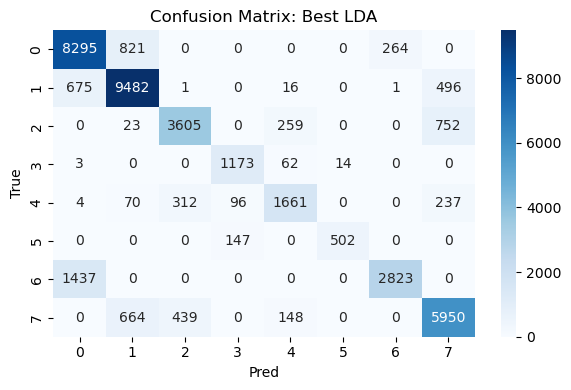

[INFO] - Classification Report:


,precision,recall,f1-score,support
alpine meadow,0.796524,0.884328,0.838133,9380.000000
alpine tundra,0.857324,0.888577,0.872670,10671.000000
bare rock,0.827404,0.777107,0.801467,4639.000000
dark rock,0.828390,0.936901,0.879310,1252.000000
scree/sunlit rock,0.773998,0.697899,0.733981,2380.000000
snow/ice,0.972868,0.773498,0.861803,649.000000
valley floor/meadow,0.914184,0.662676,0.768372,4260.000000
veg-scree mix,0.800269,0.826274,0.813064,7201.000000
,NaN,NaN,NaN,NaN
accuracy,0.828329,0.828329,0.828329,0.828329


[INFO] - Evaluation Metrics:


,Model,Error_Rate,Balanced_Accuracy,F1_score,AUC_score
0,Best LDA,0.171671,0.805908,0.826751,0.986267


In [153]:
LDA_model_info = {
    'model':  LDA(),
    'parameters': {
        'Model__solver' : ['svd', 'lsqr','eigen']
    }
}

best_LDA, best_param, best_score, gridscv_fit = train_cv( X_train=X_train,
                    y_train=y_train,
                    model_info = LDA_model_info, 
                    scale=True
                )

best_LDA_results = test(model_name = "Best LDA",
                        model_fit = best_LDA,
                        X_test=X_test,
                        y_test=y_test)

#### **PCA + LDA**

----


[WARNING] - Applying scaling for model: LinearDiscriminantAnalysis()
[INFO] - PCA is enabled
Fitting 5 folds for each of 3 candidates, totalling 15 fits
[INFO] - Best parameters: {'Model__solver': 'svd'}
[INFO] - Best CV balance score: 0.8072


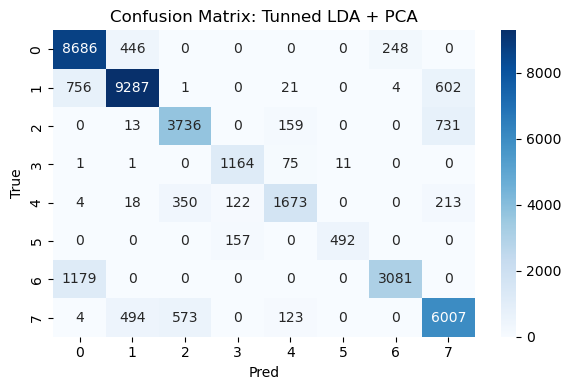

[INFO] - Classification Report:


,precision,recall,f1-score,support
alpine meadow,0.817121,0.926013,0.868166,9380.000000
alpine tundra,0.905254,0.870303,0.887434,10671.000000
bare rock,0.801717,0.805346,0.803527,4639.000000
dark rock,0.806653,0.929712,0.863822,1252.000000
scree/sunlit rock,0.815700,0.702941,0.755134,2380.000000
snow/ice,0.978131,0.758089,0.854167,649.000000
valley floor/meadow,0.924392,0.723239,0.811537,4260.000000
veg-scree mix,0.795313,0.834190,0.814288,7201.000000
,NaN,NaN,NaN,NaN
accuracy,0.844034,0.844034,0.844034,0.844034


[INFO] - Evaluation Metrics:


,Model,Error_Rate,Balanced_Accuracy,F1_score,AUC_score
0,Tunned LDA + PCA,0.155966,0.818729,0.84326,0.988166


In [154]:
pca_lda_fit, best_pca_param, best_pca_score, pca_gridscv_fit = train_cv(X_train=pcaX_train,
                    y_train=y_train,
                    model_info = LDA_model_info, 
                    scale=True,
                    use_pca = True,
                    pca_ncomp = 10
                )

pca_lda_results = test(model_name = "Tunned LDA + PCA",
                        model_fit = pca_lda_fit,
                        X_test=pcaX_test,
                        y_test=y_test)

#### **PCA and Non-PCA LDA Evaluation**

------

**Linear Decision Boundary**

LDA produces 'K classes - 1' discriminant components (7 in our case for 8 classes). Each components represents the direction in the feature space that maximises between class seperation. The class discriminant scores are obtained by projecting the data onto all these components.  

The LDA compoenents come from:

$$
w = \Sigma^{-1}(\mu_i - \mu_j)
$$

$\Sigma$ is the pooled covariance matrix, assumed common across all classes, it controls the shape, orientation and spread of the data in the transformed space -> influencing separation, direction and compactness of the LDA components.

Plotting the LDA components helps us to understand how PCA changes the linear seperability that defines LDA's decision boundary.

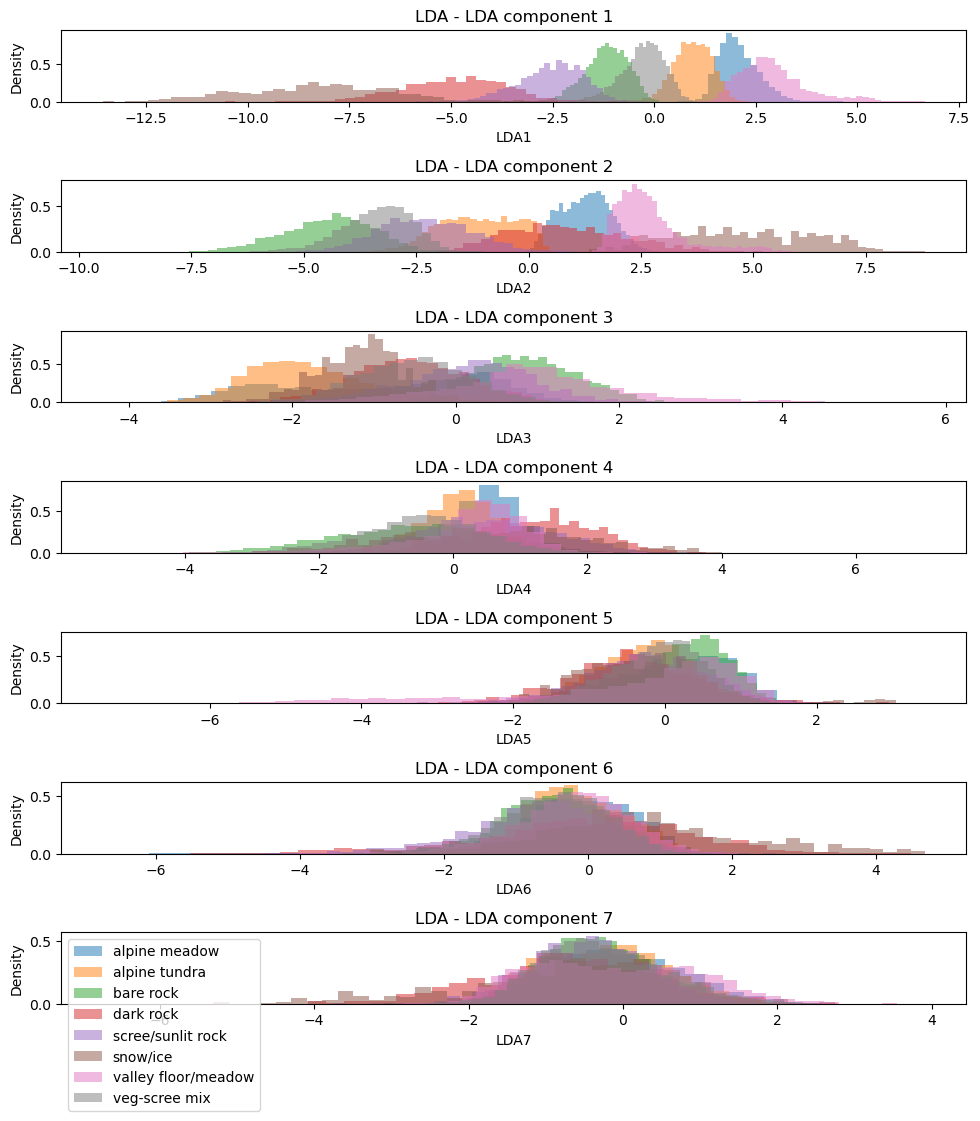

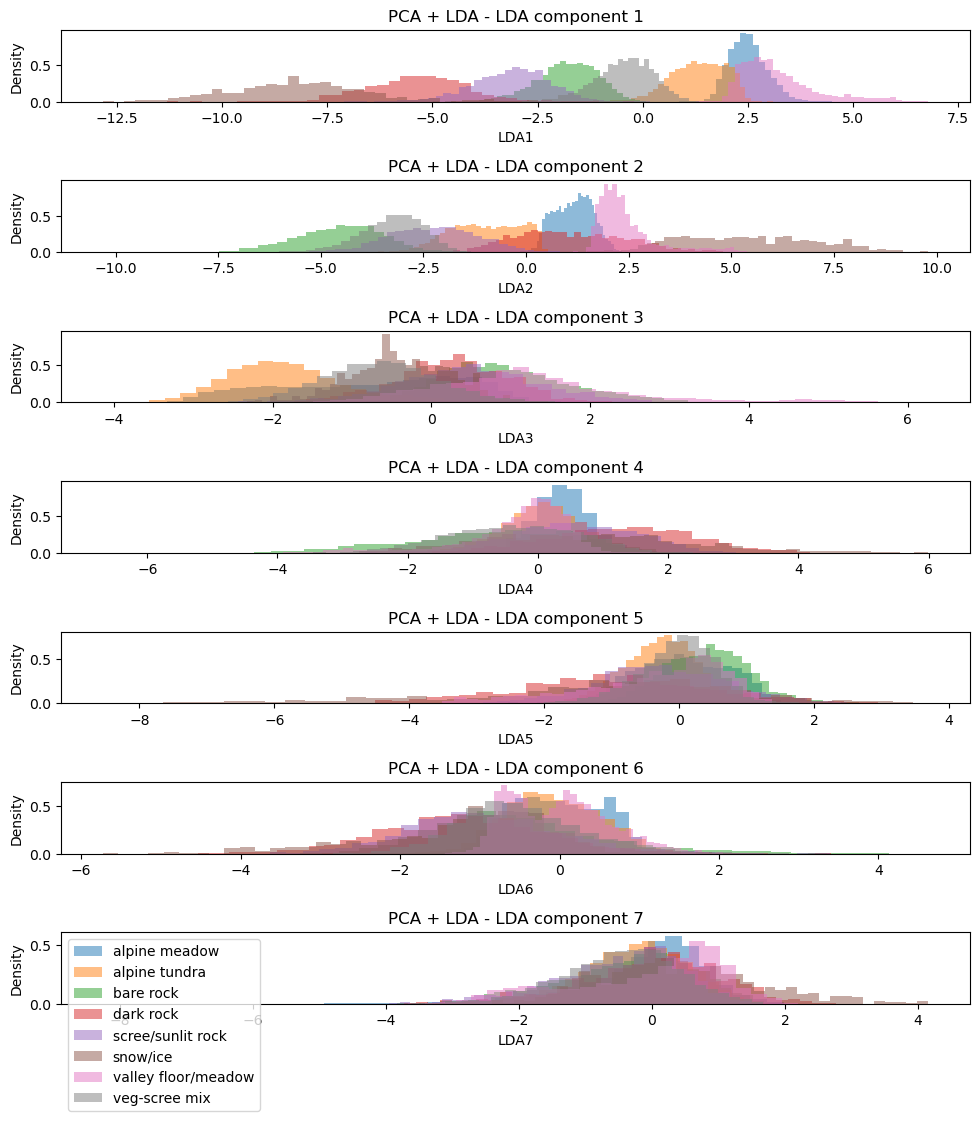

In [155]:
def lda_components(model, X, y, model_name):
    # projects X test into a LDA discriminant space

    Z = model.transform(X) # we have 8 classes so [rows, 7]
    n_components = Z.shape[1] # returns 7 for 7 total components

    # label mapping for easy vis
    label_mapping = {
        'alpine meadow': 0,
        'alpine tundra': 1,
        'bare rock': 2,
        'dark rock': 3,
        'scree/sunlit rock': 4,
        'snow/ice': 5,
        'valley floor/meadow': 6,
        'veg-scree mix': 7
            }
    
    reverse_mapping = {v: k for k, v in label_mapping.items()}

    plt.figure(figsize = (10, 11))

    # loop through each components
    for i in range(n_components):
        plt.subplot(n_components, 1, i+1)

        for label in np.unique(y):
            plt.hist(Z[y == label, i], # support samples belonging to the class
                     bins = 40, 
                     alpha = 0.5,
                     density = True,
                     label = reverse_mapping[label]
                     )
            
            plt.title(f'{model_name} - LDA component {i+1}')
            plt.xlabel(f'LDA{i+1}')
            plt.ylabel('Density')

    leg = plt.legend(loc = 'upper left')
    leg.get_frame().set_alpha(0.8)
    plt.tight_layout()
    plt.show()
            
lda_components(best_LDA, X_test, y_test, 'LDA')

lda_components(pca_lda_fit, pcaX_test, y_test, 'PCA + LDA')

For Non-PCA LDA:
- There are strong seperations between classes in LDA component 1, but with overlaps between some others like alpine, tundra and valleyfoor. LDA1 captures majority of the terrain differences and overlapping groups indicate collinearity within the feature space. 

- In LDA component 2, the seperation for class groups like alpine, tundra and valleyfloor becomes clearer, but major overlaps can be seen in other classes.

- Beyond LDA component 3, the overlaps dominated almost all classes, with weap seperation across classes; providing unusable signals or noise to the model

- The components plot for Non-PCA LDA confirms that the feature space is noisy and the share covariance assumption is violated.

For PCA LDA:
- PCA removed noises and correlated dimensions, which makes the shared covariance matrix more stable. Therefore, we see LDA component 1 having better class seperation. (Sharper peaks -> less overlaps)

- Similar to component 1, classes have sharper peaks and less overlaps -> better seperation between classes

- Beyond LDA component 3, the sharper peaks make difference classes more noticeable but not by a lot, there are still strong overlaps, sends less unsuable signals but are still noise to the model.

- The improvement in removing noise and correlated dimensions made PCA-LDA produce better predictions but not by a whole lot as componenet 3 onwards are still noisy


-----

### **b. Logistic Regression**

- Despite reducing the number of features using hierarchical clustering there still exist multicollinearity within the features. Therefore, some form of penalisation of multicollinearity is required within the model

- Within the pairplot show above, 4 to 5 classes can be easily seperated. However there is still major forms of overlapping within the other classes. Therefore, we use small regularisation strength 0.1 to 1.0 with 1.0 being the default value.

- dataset is large and sparse. -> saga (supports l1, l2 and elastic net)

------

[WARNING] - Applying scaling for model: LogisticRegression(max_iter=5000)
[INFO] - PCA is toggled off
Fitting 5 folds for each of 15 candidates, totalling 75 fits
[INFO] - Best parameters: {'Model__C': 1.0, 'Model__penalty': 'l1', 'Model__solver': 'saga'}
[INFO] - Best CV balance score: 0.9632


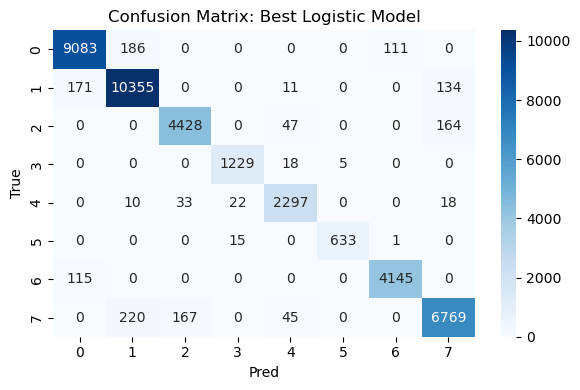

[INFO] - Classification Report:


,precision,recall,f1-score,support
alpine meadow,0.969474,0.968337,0.968905,9380.000000
alpine tundra,0.961378,0.970387,0.965861,10671.000000
bare rock,0.956785,0.954516,0.955649,4639.000000
dark rock,0.970774,0.981629,0.976172,1252.000000
scree/sunlit rock,0.949959,0.965126,0.957482,2380.000000
snow/ice,0.992163,0.975347,0.983683,649.000000
valley floor/meadow,0.973690,0.973005,0.973347,4260.000000
veg-scree mix,0.955399,0.940008,0.947641,7201.000000
,NaN,NaN,NaN,NaN
accuracy,0.963074,0.963074,0.963074,0.963074


[INFO] - Evaluation Metrics:


,Model,Error_Rate,Balanced_Accuracy,F1_score,AUC_score
0,Best Logistic Model,0.036926,0.966044,0.963052,0.999229


In [156]:
logit_info = {
    'model': LogisticRegression(max_iter=5000),
    'parameters': [
        {
        'Model__penalty': ['l1','l2'],
        'Model__C': [0.1,0.5,1.0],
        'Model__solver': ['saga']
    },
    
    # seperate grid search for elastic net to specify l1 ratio
    {
        'Model__penalty': ['elasticnet'],
        'Model__C': [0.1, 0.5, 1.0],
        'Model__solver': ['saga'],
        'Model__l1_ratio': [0.2, 0.5, 0.8] # 0 = using L2, 1 = using L1
    }
    ]
}

best_logfit, best_param, best_score, gridscv_fit = train_cv( X_train=X_train,
                    y_train=y_train,
                    model_info = logit_info, 
                    scale=True
                )

best_logfit_results = test(model_name = "Best Logistic Model",
                        model_fit = best_logfit,
                        X_test=X_test,
                        y_test=y_test)


#### **PCA + Logistic Regression**

-----

[WARNING] - Applying scaling for model: LogisticRegression(max_iter=5000)
[INFO] - PCA is enabled
Fitting 5 folds for each of 15 candidates, totalling 75 fits
[INFO] - Best parameters: {'Model__C': 1.0, 'Model__penalty': 'l1', 'Model__solver': 'saga'}
[INFO] - Best CV balance score: 0.9813


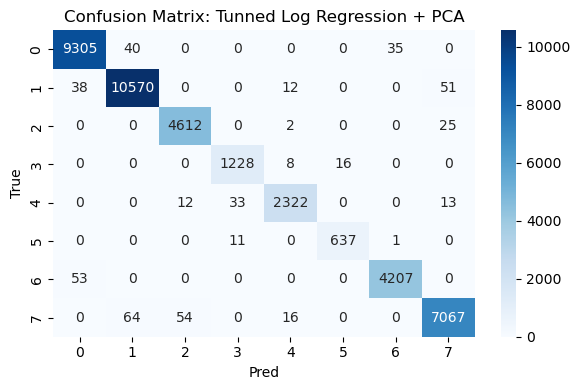

[INFO] - Classification Report:


,precision,recall,f1-score,support
alpine meadow,0.990315,0.992004,0.991159,9380.000000
alpine tundra,0.990257,0.990535,0.990396,10671.000000
bare rock,0.985891,0.994180,0.990018,4639.000000
dark rock,0.965409,0.980831,0.973059,1252.000000
scree/sunlit rock,0.983898,0.975630,0.979747,2380.000000
snow/ice,0.975498,0.981510,0.978495,649.000000
valley floor/meadow,0.991515,0.987559,0.989533,4260.000000
veg-scree mix,0.987563,0.981391,0.984468,7201.000000
,NaN,NaN,NaN,NaN
accuracy,0.988029,0.988029,0.988029,0.988029


[INFO] - Evaluation Metrics:


,Model,Error_Rate,Balanced_Accuracy,F1_score,AUC_score
0,Tunned Log Regression + PCA,0.011971,0.985455,0.988028,0.999878


In [157]:
pca_best_logfit, best_pca_param, best_pca_score, pca_gridscv_fit = train_cv(X_train=pcaX_train,
                    y_train=y_train,
                    model_info = logit_info, 
                    scale=True,
                    use_pca = True,
                    pca_ncomp = 10
                )

pca_logfit_results = test(model_name = "Tunned Log Regression + PCA",
                        model_fit = pca_best_logfit,
                        X_test=pcaX_test,
                        y_test=y_test)

#### **PCA and Non-PCA Log Reg Evaluation**

Coefficients's from Logistic Regressions provide a strong way to compare the behaviour between PCA and Non-PCA Log Reg. We examined the coefficients magnitute and class specific patterns to evaluate the linear seperability of dimensionality reduced Log Reg vs one that uses the raw dataset. 

--------

In [158]:
# dynamic function for multi-log and binary (for glacier detection later on)
def logreg_coef(model_name, model, feature_names=None):
    # store coefficients
    coefficients = None
    
    label_mapping = {
    'alpine meadow': 0,
    'alpine tundra': 1,
    'bare rock': 2,
    'dark rock': 3,
    'scree/sunlit rock': 4,
    'snow/ice': 5,
    'valley floor/meadow': 6,
    'veg-scree mix': 7
        }

    reverse_mapping = {v: k for k, v in label_mapping.items()}
    
    # check if model is in pipeline (used in cv function)
    if isinstance(model, Pipeline):
        # get final estimates
        best_estimates = model.steps[-1][1]

        # extract coefficients
        coefficients = best_estimates.coef_
    
    # else model is on its own (used in glacier detection)
    else:
        coefficients = model.coef_

    if coefficients is None:
        log(f'{model_name} does not have coefficients', 'warning')
        return

    n_classes = coefficients.shape[0]
    n_features = coefficients.shape[1]
    
    # average absolute coefficient as importance
    importance = np.mean(np.abs(coefficients), axis=0)
    
    # sort and get top 20 important features
    sorted_idx = np.argsort(importance)[::-1]
    top_n = min(20, n_features) 
    top_idx = sorted_idx[:top_n]
    
    fig, axes = plt.subplots(1, 2, figsize=(16, 6))
    
    # left plot: importance
    fig.axes[0].barh(range(top_n), importance[top_idx])
    fig.axes[0].set_yticks(range(top_n))
    fig.axes[0].set_yticklabels([feature_names[i] for i in top_idx])
    fig.axes[0].set_xlabel('Importance (Abs Mean Coef)')
    fig.axes[0].set_title(f'{model_name}: Feature Importance Across Classes')
    fig.axes[0].invert_yaxis()
    
    # right plot: heatmap of coefficients per class
    coef_subset = coefficients[:, top_idx].T
    im = axes[1].imshow(coef_subset, aspect='auto', cmap='RdBu_r', 
                        vmin=-np.max(np.abs(coef_subset)), 
                        vmax=np.max(np.abs(coef_subset)))
    
    class_labels = [reverse_mapping[c] for c in range(n_classes)]

    axes[1].set_yticks(range(top_n))
    axes[1].set_yticklabels([feature_names[i] for i in top_idx])
    axes[1].set_xticks(range(n_classes))
    axes[1].set_xticklabels(class_labels, rotation = 45, ha='right')
    axes[1].set_xlabel('Class')
    axes[1].set_title(f'{model_name}: Heatmap of Coefficients by Classes')
    plt.colorbar(im, ax=axes[1])
    
    plt.tight_layout()
    plt.show()

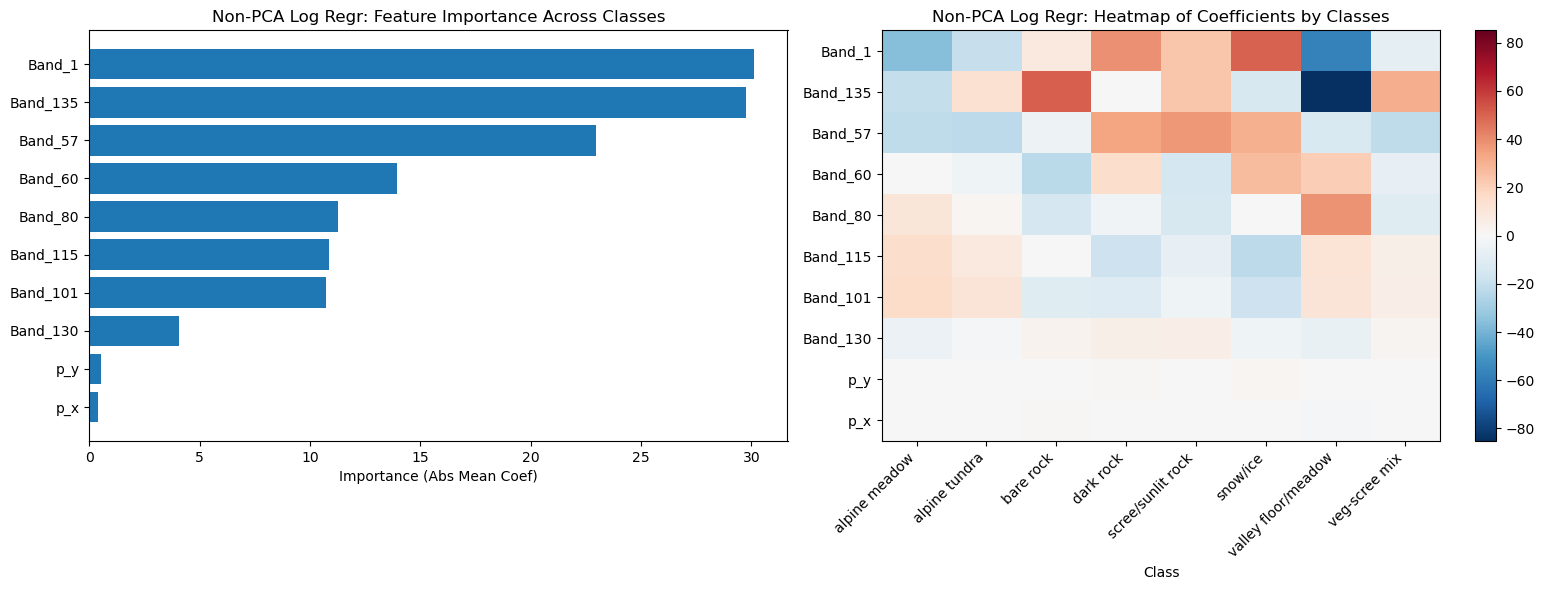

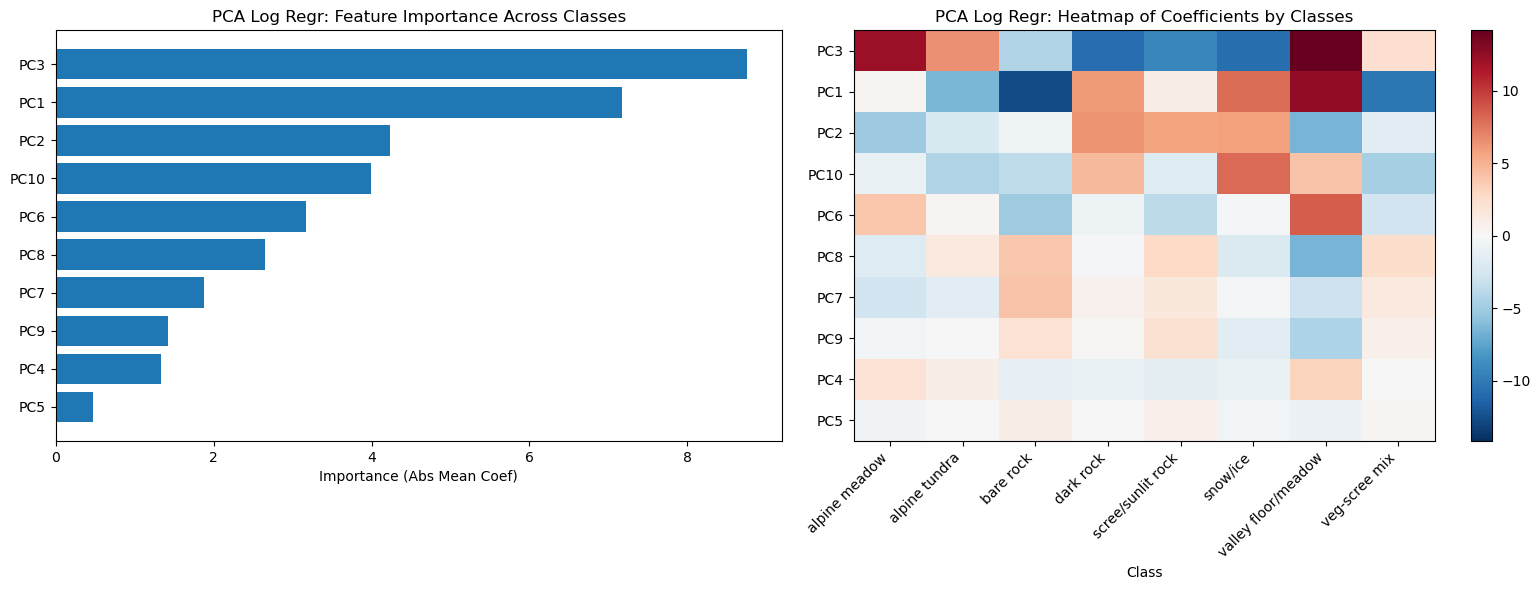

In [159]:
# non-pca log regression
logreg_coef(model_name='Non-PCA Log Regr',
    model=best_logfit,
    feature_names=X_train.columns.tolist()
)

# pca log regression
pca = pca_best_logfit.named_steps['PCA']
logreg_coef(model_name='PCA Log Regr',
    model=pca_best_logfit,
    feature_names=[f'PC{i+1}' for i in range(pca.n_components_)]
)

### **c. Quadratic Discriminant Analysis (QDA)**

QDA estimates a single covariance matrix per class and the quadratic decision boundary is defined as:

$$
(x - \mu_k)^T \Sigma_k^{-1} (x - \mu_k)
$$

However, when features are highly correlated, the covariance matrix becomes near singular, this forms a greater risk than LDA, as the inverted covariance matrix of each class will become very extreme causing the boundaries to be extreme -> inaccurate predictions (overfitted on noise).

A regularised covariance matrix prevents this, by shrinking the covariance matrix, stabilising the inversion.

$$
\Sigma_k^{\text{reg}} = (1 - \lambda)\Sigma_k + \lambda I
$$

where lambda (*notation here its not eigenvalue) is the regularisation strength ('reg_param')


------

[WARNING] - Applying scaling for model: QuadraticDiscriminantAnalysis(store_covariance=True)
[INFO] - PCA is toggled off
Fitting 5 folds for each of 5 candidates, totalling 25 fits
[INFO] - Best parameters: {'Model__reg_param': 0.0}
[INFO] - Best CV balance score: 0.8620


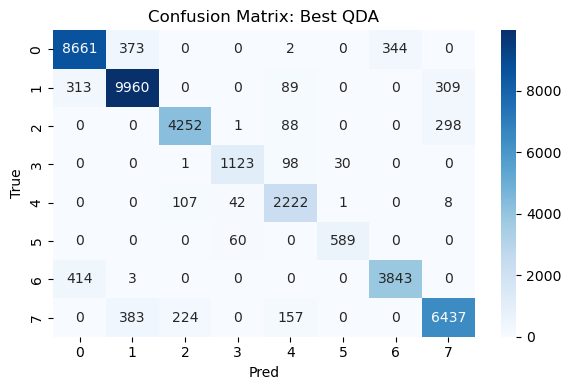

[INFO] - Classification Report:


,precision,recall,f1-score,support
alpine meadow,0.922561,0.923348,0.922954,9380.000000
alpine tundra,0.929191,0.933371,0.931276,10671.000000
bare rock,0.927574,0.916577,0.922043,4639.000000
dark rock,0.915987,0.896965,0.906376,1252.000000
scree/sunlit rock,0.836596,0.933613,0.882446,2380.000000
snow/ice,0.950000,0.907550,0.928290,649.000000
valley floor/meadow,0.917841,0.902113,0.909909,4260.000000
veg-scree mix,0.912791,0.893904,0.903248,7201.000000
,NaN,NaN,NaN,NaN
accuracy,0.917269,0.917269,0.917269,0.917269


[INFO] - Evaluation Metrics:


,Model,Error_Rate,Balanced_Accuracy,F1_score,AUC_score
0,Best QDA,0.082731,0.91343,0.91735,0.994507


In [160]:
QDA_model_info = {
    'model': QDA(store_covariance = True),
    'parameters': {
        'Model__reg_param' : [0.0,0.1,0.5,0.75,1] # 0 = no regularisation, 1 = max shrinkage
    }
}

best_QDA, best_param, best_score, gridscv_fit = train_cv( X_train=X_train,
                    y_train=y_train,
                    model_info = QDA_model_info, 
                    scale=True
                )

best_QDA_results = test(model_name = "Best QDA",
                        model_fit = best_QDA,
                        X_test=X_test,
                        y_test=y_test)

#### **PCA + QDA**

-----

[WARNING] - Applying scaling for model: QuadraticDiscriminantAnalysis(store_covariance=True)
[INFO] - PCA is enabled
Fitting 5 folds for each of 5 candidates, totalling 25 fits
[INFO] - Best parameters: {'Model__reg_param': 0.5}
[INFO] - Best CV balance score: 0.9493


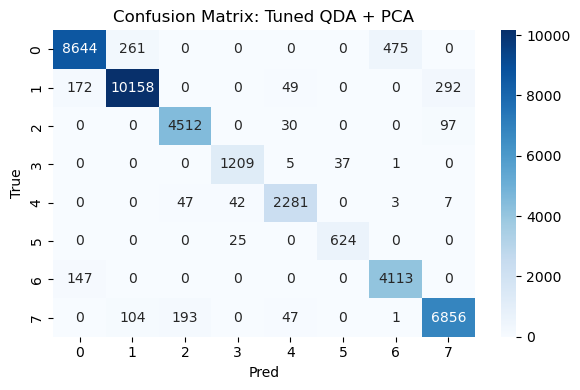

[INFO] - Classification Report:


,precision,recall,f1-score,support
alpine meadow,0.964409,0.921535,0.942485,9380.000000
alpine tundra,0.965314,0.951926,0.958573,10671.000000
bare rock,0.949495,0.972623,0.960920,4639.000000
dark rock,0.947492,0.965655,0.956487,1252.000000
scree/sunlit rock,0.945688,0.958403,0.952003,2380.000000
snow/ice,0.944024,0.961479,0.952672,649.000000
valley floor/meadow,0.895493,0.965493,0.929177,4260.000000
veg-scree mix,0.945394,0.952090,0.948730,7201.000000
,NaN,NaN,NaN,NaN
accuracy,0.949669,0.949669,0.949669,0.949669


[INFO] - Evaluation Metrics:


,Model,Error_Rate,Balanced_Accuracy,F1_score,AUC_score
0,Tuned QDA + PCA,0.050331,0.956151,0.949714,0.998511


In [161]:
pca_QDA, best_pcaparam, best_pcascore, qda_gridscv_fit = train_cv( X_train=pcaX_train,
                                                        y_train=y_train,
                                                        model_info = QDA_model_info, 
                                                        scale=True,
                                                        use_pca=True,
                                                        pca_ncomp = 10
                                                    )

best_pcaQDA_results = test(model_name = "Tuned QDA + PCA",
                        model_fit = pca_QDA,
                        X_test=pcaX_test,
                        y_test=y_test)

#### **PCA vs Non-PCA QDA Evaluation**

------

**Quadratic Boundaries**

A well conditioned covariance matrix has smooth curves while a near singular one has sharp peaks and often unstable curves as these boundaries are overfitted on the noise of the data.

To explore into the curvatures and the covariance matrix condition of PCA and  the non-PCA QDA model, we extract the covariances obtained by the model and performed 2 quantitative measures:

1. Pairwise measure of the difference in 2 classes' (i and j) inverse covariance matrix as it is what determines the shape of the boundaries. We did this by using Frobenius Norm (euclidean distance of a matrix flatten into a vector). The magnitude will give us an understadning of how different the 2 quadratic surfaces are.

2. Condition Numbers of covariances. This measures takes eigenvalue(max)/eigenvalue(min) and it returns the stability measure of the covariance matrix.

In [162]:
def qda_boundary(model, model_name):
    covariances = model.named_steps['Model'].covariance_
    n_classes = len(covariances)

    curvature = {} # store curvature

    label_mapping = {
    'alpine meadow': 0,
    'alpine tundra': 1,
    'bare rock': 2,
    'dark rock': 3,
    'sunlit rock': 4,
    'snow': 5,
    'valley floor': 6,
    'veg-scree mix': 7
        }

    reverse_mapping = {v: k for k, v in label_mapping.items()}

    for i in range(n_classes):
        for j in range(i + 1, n_classes):

            # inverse cov matrices
            E_i = np.linalg.inv(covariances[i])
            E_j = np.linalg.inv(covariances[j])

            # shape of the boundary
            boundary_shape = E_i - E_j
            
            # using the frobenius norm to get the curvature measure
            curvature[(i, j)] = np.linalg.norm(boundary_shape, 'fro')

    cov_stability = [np.linalg.cond(C) for C in covariances] # measures the stability of the covariance matrix

    labels = [f'{reverse_mapping[i]}-{reverse_mapping[j]}' for (i, j) in curvature.keys()]
    values = list(curvature.values())

    # curvature plot
    plt.figure(figsize = (8, 5))
    
    plt.bar(range(len(values)),
            values,
            color = 'blue',
            alpha = 0.7
            )
    
    plt.xticks(range(len(values)),
               labels,
               rotation = 45,
               ha = 'right'
               )
    
    plt.ylabel('E_i - E_j (Inversed)')
    plt.title(f'Boundary Curvature {model_name}')
    plt.tight_layout()
    plt.show()

    # plot condition number
    plt.figure(figsize = (8, 5))
    plt.bar([reverse_mapping[i] for i in range(n_classes)],
            cov_stability,
            color = 'red',
            alpha = 0.7
        )
    plt.xticks(rotation = 45)
    plt.ylabel('Condition Numbers')
    plt.title(f'Covariance Stability {model_name}')
    plt.tight_layout()
    plt.show()

    return curvature, cov_stability

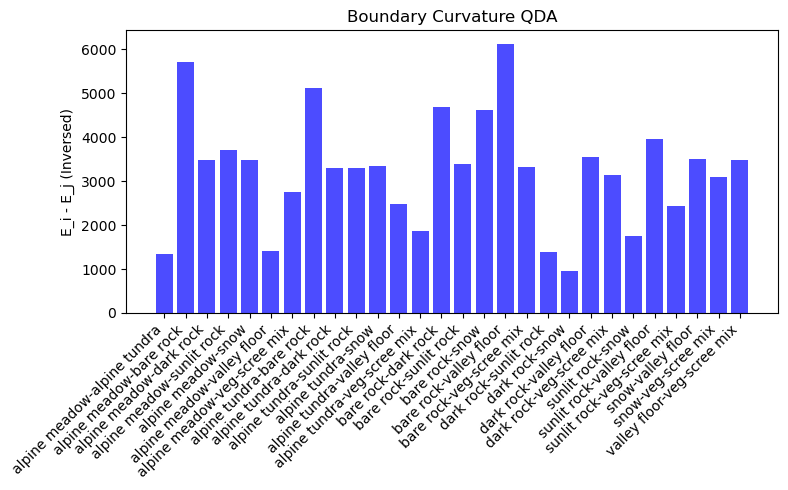

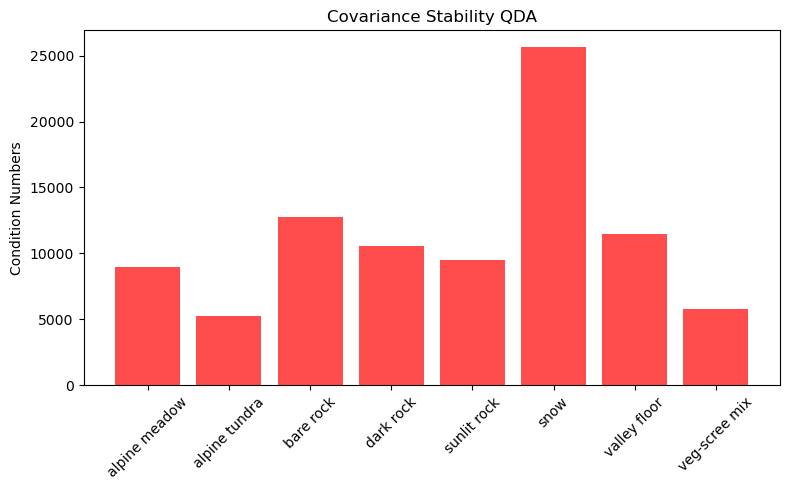

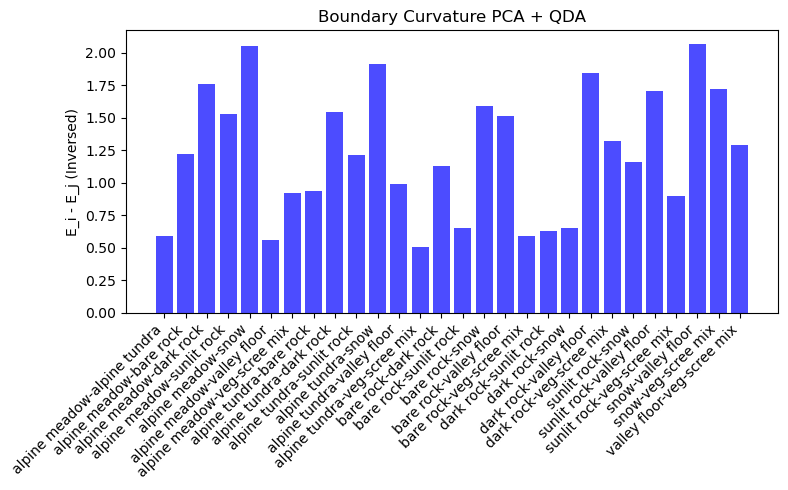

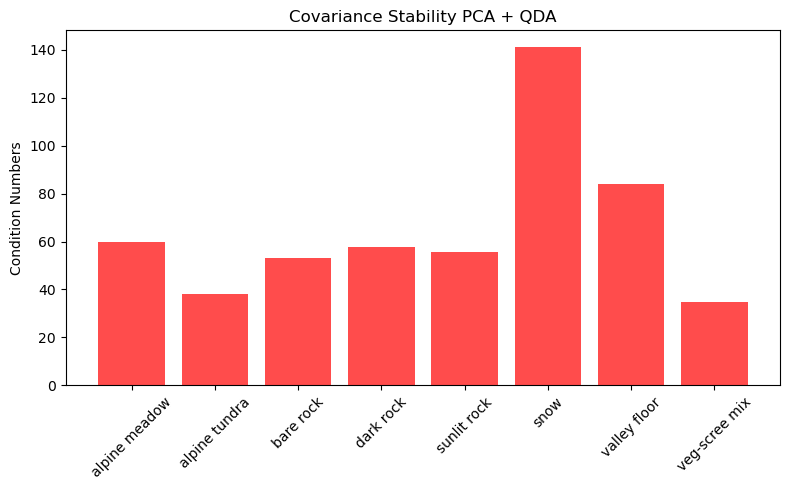

In [163]:
curvature_qda, stability_qda = qda_boundary(best_QDA, "QDA")
curvature_pca_qda, stability_pca_qda = qda_boundary(pca_QDA, "PCA + QDA")

Non-PCA QDA:
- Curvature plot shows high magnitude of values ranging from 1000 - 6000. This means that the covariance matrices are very different across classes and the boundaries are very curved. The seperation between each classes are complex. While, this is a perk of QDA when comparing with LDA, QDA fitting on a very complex shape might run the risk of overfitting 

- Stability plot also showed high values of condition numbers, with snow being approximately 25,000. The max eigenvalue is dominating the min and the covariance matrix is very close to bing singular and the inverse of it becomes unstable. Again this will lead to extreme boundaries, fitting noises.

PCA QDA:
- While the shape of the plots are not too far off from the Non-PCA QDA. All values have dramatically dropped. Covariance matrice of each class becomes more well-conditioned. Curvature of the decision boundary becomes smooth and QDA becomes more robust.

------


### **d. K Nearest Neighbours**
------

[WARNING] - Applying scaling for model: KNeighborsClassifier()
[INFO] - PCA is toggled off
Fitting 5 folds for each of 80 candidates, totalling 400 fits
[INFO] - Best parameters: {'Model__metric': 'manhattan', 'Model__n_neighbors': 12, 'Model__weights': 'distance'}
[INFO] - Best CV balance score: 0.9323


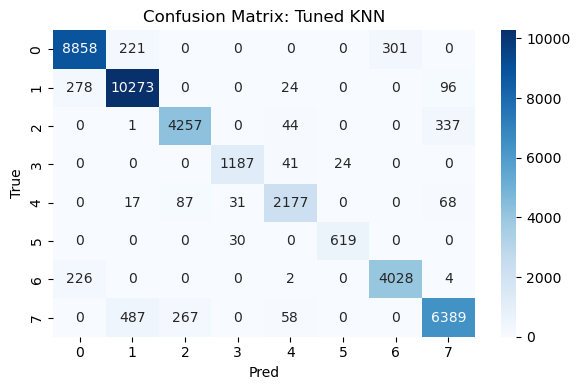

[INFO] - Classification Report:


,precision,recall,f1-score,support
alpine meadow,0.946165,0.944350,0.945257,9380.000000
alpine tundra,0.933994,0.962703,0.948131,10671.000000
bare rock,0.923227,0.917655,0.920432,4639.000000
dark rock,0.951122,0.948083,0.949600,1252.000000
scree/sunlit rock,0.927962,0.914706,0.921287,2380.000000
snow/ice,0.962675,0.953775,0.958204,649.000000
valley floor/meadow,0.930469,0.945540,0.937944,4260.000000
veg-scree mix,0.926748,0.887238,0.906563,7201.000000
,NaN,NaN,NaN,NaN
accuracy,0.934606,0.934606,0.934606,0.934606


[INFO] - Evaluation Metrics:


,Model,Error_Rate,Balanced_Accuracy,F1_score,AUC_score
0,Tuned KNN,0.065394,0.934256,0.934436,0.997128


In [164]:
# gridsearch CV approach
knn_model_info = {
    'model': KNeighborsClassifier(),
    'parameters': {
        'Model__n_neighbors': list(range(1, 21)), # train across 1 - 20 neighbours
        'Model__weights': ['uniform', 'distance'],
        'Model__metric': ['minkowski', 'manhattan']
    }
}

best_knn, best_param, best_score, knn_cv_fit = train_cv( X_train=X_train,
                    y_train=y_train,
                    model_info = knn_model_info, 
                    scale=True
                )

best_knn_results = test(model_name = "Tuned KNN",
                        model_fit = best_knn,
                        X_test=X_test,
                        y_test=y_test)

#### **PCA + KNN**

------

[WARNING] - Applying scaling for model: KNeighborsClassifier()
[INFO] - PCA is enabled
Fitting 5 folds for each of 80 candidates, totalling 400 fits
[INFO] - Best parameters: {'Model__metric': 'minkowski', 'Model__n_neighbors': 16, 'Model__weights': 'distance'}
[INFO] - Best CV balance score: 0.9684


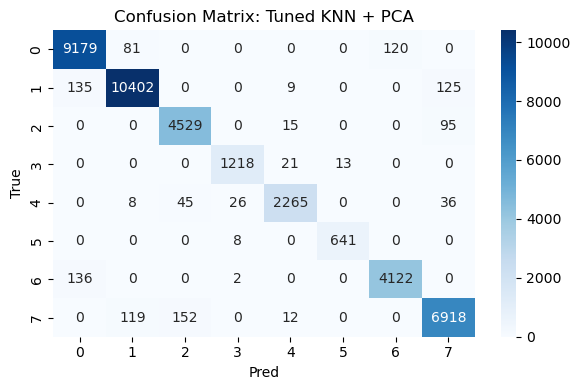

[INFO] - Classification Report:


,precision,recall,f1-score,support
alpine meadow,0.971323,0.978571,0.974934,9380.000000
alpine tundra,0.980396,0.974791,0.977586,10671.000000
bare rock,0.958316,0.976288,0.967218,4639.000000
dark rock,0.971292,0.972843,0.972067,1252.000000
scree/sunlit rock,0.975452,0.951681,0.963420,2380.000000
snow/ice,0.980122,0.987673,0.983883,649.000000
valley floor/meadow,0.971711,0.967606,0.969654,4260.000000
veg-scree mix,0.964316,0.960700,0.962504,7201.000000
,NaN,NaN,NaN,NaN
accuracy,0.971359,0.971359,0.971359,0.971359


[INFO] - Evaluation Metrics:


,Model,Error_Rate,Balanced_Accuracy,F1_score,AUC_score
0,Tuned KNN + PCA,0.028641,0.971269,0.971356,0.999569


In [165]:
pca_knn, best_pcaparam, best_pcascore, knn_cv_fit = train_cv( X_train=pcaX_train,
                                                        y_train=y_train,
                                                        model_info = knn_model_info, 
                                                        scale=True,
                                                        use_pca=True,
                                                        pca_ncomp = 10
                                                    )

best_pcaknn_results = test(model_name = "Tuned KNN + PCA",
                        model_fit = pca_knn,
                        X_test=pcaX_test,
                        y_test=y_test)

### **e. Random Forest**
-------

Random Forest builds trees using bootstrapping. Around 1/3 of the observations that are not used in the construction of each individual trees are used as Out of Bag (OOB) samples. After a tree is built, it can make predictions on these OOB samples; This provides an internal estimate of the model accuracy. 

Therefore, instead of using CV we use this built in form of CV, which is faster to determine the optimal number of trees.

- Under the **ISLR**, it suggests to treat the max_feature parameter as sqrt(N). Therefore, we will not be experimenting on that and only explore on the number of trees to use during this OOB score exploration.

- *To Tune or Not to Tune the Number of Trees in Random Forest by Philipp Probst & Anne-Laure (2018)* found performance of trees plateaus after 128 trees and post on ([stackexchange](https://stats.stackexchange.com/questions/36165/does-the-optimal-number-of-trees-in-a-random-forest-depend-on-the-number-of-pred?)) recommends 64-128

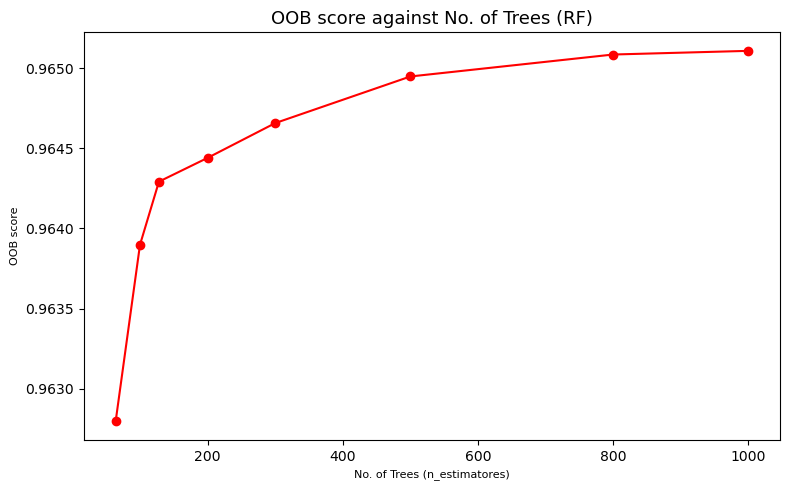

In [166]:
# more trees does not = overfitting
n_trees = [64, 100, 128, 200, 300, 500, 800, 1000]

# storing oob scores
oob_scores = []
oob_rf_models = {} # store trained models

# loop through n_trees for training, returning OOB
for n in n_trees: 
    oob_rf = RandomForestClassifier(n_estimators = n, 
                                oob_score = True, # toggle on OOB
                                random_state = 101,
                                n_jobs = -1 
    )

    oob_rf.fit(X_train, y_train)
    oob_scores.append(oob_rf.oob_score_)

    # save model by n_trees
    oob_rf_models[n] = oob_rf

# plot oob scores
plt.figure (figsize = (8, 5))
plt.plot(n_trees,
         oob_scores,
         marker = 'o',
         color = 'red'
         )

# plot config
plt.title('OOB score against No. of Trees (RF)', fontsize = 13)
plt.xlabel('No. of Trees (n_estimatores)', fontsize = 8)
plt.ylabel('OOB score', fontsize = 8)
plt.tight_layout()
plt.show()

Observing a diminishin return in OOB score after 500+ trees, indicating adding more trees provide minimal improvement in model performance. Between 64 and 200 trees, the OOB score appears unstable.
 
Therefore, the sweet spot for the number or trees is between 200 and 500. Based on the elbow method the best number of trees is 300. 

Using Cross Validation (40 mins)

- CV is slower as compared to OOB score, but it allows us to loop across various combination of parameters to look for the best RF model. 

- As CV is computationally intensive, OOB score analysis allowed us to narrow down the search for the number of trees.

[WARNING] - Scaling is turned off: Scale = False, for RandomForestClassifier()
[INFO] - PCA is toggled off
Fitting 5 folds for each of 36 candidates, totalling 180 fits
[INFO] - Best parameters: {'Model__max_features': 'sqrt', 'Model__min_samples_leaf': 1, 'Model__min_samples_split': 2, 'Model__n_estimators': 500, 'Model__random_state': 101}
[INFO] - Best CV balance score: 0.9601


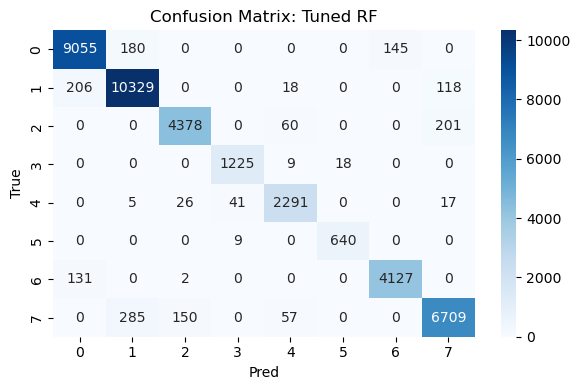

[INFO] - Classification Report:


,precision,recall,f1-score,support
alpine meadow,0.964118,0.965352,0.964735,9380.000000
alpine tundra,0.956477,0.967951,0.962180,10671.000000
bare rock,0.960931,0.943738,0.952257,4639.000000
dark rock,0.960784,0.978435,0.969529,1252.000000
scree/sunlit rock,0.940862,0.962605,0.951610,2380.000000
snow/ice,0.972644,0.986133,0.979342,649.000000
valley floor/meadow,0.966058,0.968779,0.967417,4260.000000
veg-scree mix,0.952307,0.931676,0.941878,7201.000000
,NaN,NaN,NaN,NaN
accuracy,0.958498,0.958498,0.958498,0.958498


[INFO] - Evaluation Metrics:


,Model,Error_Rate,Balanced_Accuracy,F1_score,AUC_score
0,Tuned RF,0.041502,0.963083,0.958451,0.99909


In [167]:
rf_model_info = {
    'model': RandomForestClassifier(),
    'parameters': {
        'Model__n_estimators': [300, 500],
        'Model__max_features': ['sqrt', 'log2'],
        'Model__min_samples_leaf': [1, 4, 10],
        'Model__min_samples_split': [2, 5, 10],
        'Model__random_state': [101]
    }
}

best_rf, best_param, best_score, gridscv_fit = train_cv( X_train=X_train,
                    y_train=y_train,
                    model_info = rf_model_info
                )

best_rf_results = test(model_name = "Tuned RF",
                        model_fit = best_rf,
                        X_test=X_test,
                        y_test=y_test)

#### **PCA + Random Forest**

----

[WARNING] - Scaling is turned off: Scale = False, for RandomForestClassifier()
[INFO] - PCA is enabled
Fitting 5 folds for each of 16 candidates, totalling 80 fits
[INFO] - Best parameters: {'Model__max_features': 'sqrt', 'Model__min_samples_leaf': 1, 'Model__min_samples_split': 5, 'Model__n_estimators': 300, 'Model__random_state': 101}
[INFO] - Best CV balance score: 0.8735


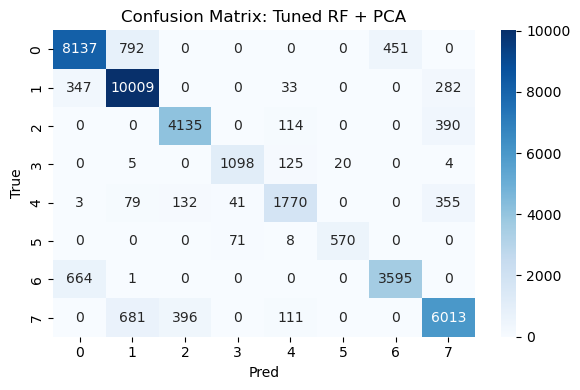

[INFO] - Classification Report:


,precision,recall,f1-score,support
alpine meadow,0.889192,0.867484,0.878204,9380.000000
alpine tundra,0.865306,0.937963,0.900171,10671.000000
bare rock,0.886768,0.891356,0.889056,4639.000000
dark rock,0.907438,0.876997,0.891958,1252.000000
scree/sunlit rock,0.819065,0.743697,0.779564,2380.000000
snow/ice,0.966102,0.878274,0.920097,649.000000
valley floor/meadow,0.888532,0.843897,0.865639,4260.000000
veg-scree mix,0.853634,0.835023,0.844226,7201.000000
,NaN,NaN,NaN,NaN
accuracy,0.873739,0.873739,0.873739,0.873739


[INFO] - Evaluation Metrics:


,Model,Error_Rate,Balanced_Accuracy,F1_score,AUC_score
0,Tuned RF + PCA,0.126261,0.859336,0.873163,0.991697


In [168]:
pca_rf_info = {
    'model': RandomForestClassifier(),
    'parameters': {
        'Model__n_estimators': [300, 500],
        'Model__max_features': ['sqrt', 'log2'],
        'Model__min_samples_leaf': [1, 4],
        'Model__min_samples_split': [2, 5],
        'Model__random_state': [101]
    }
}

pca_rf, best_pcaparam, best_pcascore, rf_cv_fit = train_cv( X_train=pcaX_train,
                                                        y_train=y_train,
                                                        model_info = pca_rf_info,
                                                        use_pca=True,
                                                        pca_ncomp = 10
                                                    )

best_pcarf_results = test(model_name = "Tuned RF + PCA",
                        model_fit = pca_rf,
                        X_test=pcaX_test,
                        y_test=y_test)

#### **PCA vs Non-PCA RF Evaluation**

-----

**1. Tree Complexity**

Comparing the distribution between the depths of trees


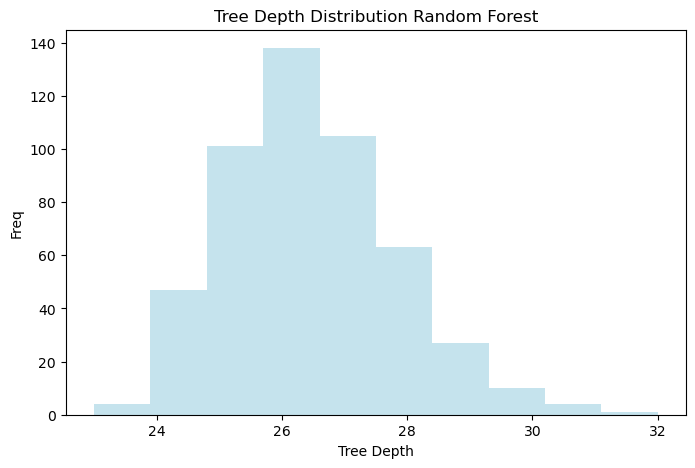

[INFO] - Mean depth: 26.34
[INFO] - Std depth: 1.52


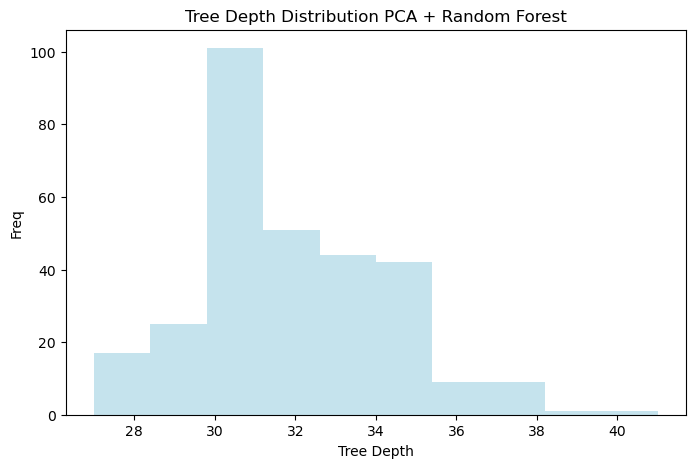

[INFO] - Mean depth: 31.87
[INFO] - Std depth: 2.30


In [169]:
def tree_depths(model, model_name):
    rf = model.named_steps['Model']

    depths = [estimator.tree_.max_depth for estimator in rf.estimators_]

    plt.figure(figsize = (8,5))
    
    # distribution
    plt.hist(depths, bins = 10, alpha = 0.7, color = 'lightblue') 

    plt.title(f'Tree Depth Distribution {model_name}')
    plt.xlabel('Tree Depth')
    plt.ylabel('Freq')
    plt.show()

    log(f'Mean depth: {np.mean(depths):.2f}', 'info')
    log(f'Std depth: {np.std(depths):.2f}', 'info')

tree_depths(best_rf, 'Random Forest')
tree_depths(pca_rf, 'PCA + Random Forest')

For Non-PCA Random Forest:

- Distribution plot shows tree depths concentrated at 24 to 27. The Non-PCA model also has a lower SD in its distribution than the PCA RF. This suggest that Random Forest repeatedly build trees of similar depths. The the model is confident in where to apply the split and is able to consistently build shallower trees. This is due to the feature selection that was done which selects the spectra bands using hierrchical clustering, we were able to capture information that seperates the classes well and the model is also able to handle the issue of mulitcollinearity within the dataset.


For PCA Random Forest:

- We see a higher frequency of deeper trees (27 -30) and a higher variation in depths. Deeper trees work well for Random Forest models as each tree is trained independently on bootstrapped data and random subsets of features, making it prone to overfitting. These deeper trees, ensemble into strong learners which provides higher predictive power for Random Forest. This explains the increase in accuracy for PCA Random Forest model.

- However, the broader distribution indicates lower confidence in split decisions are applying PCA.

-----

**2. Variance of Feature Importance**

Examine consistency of each feature's importance is across trees

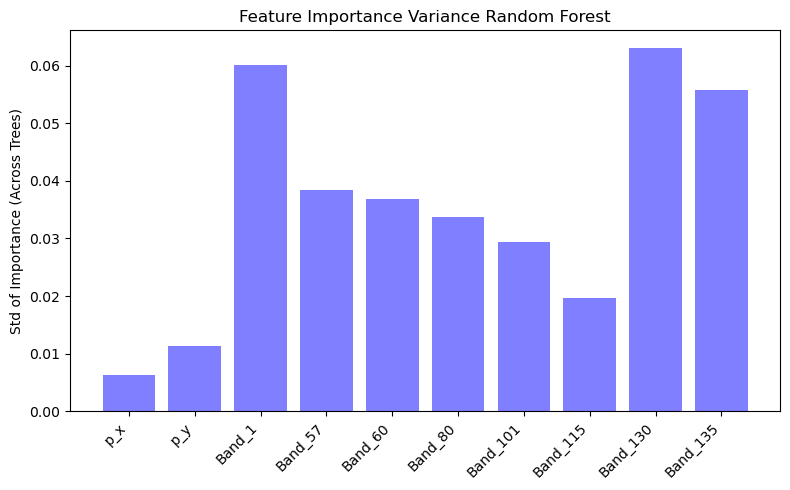

[INFO] - Average Variability: 0.04
[INFO] - Max Variability: 0.06


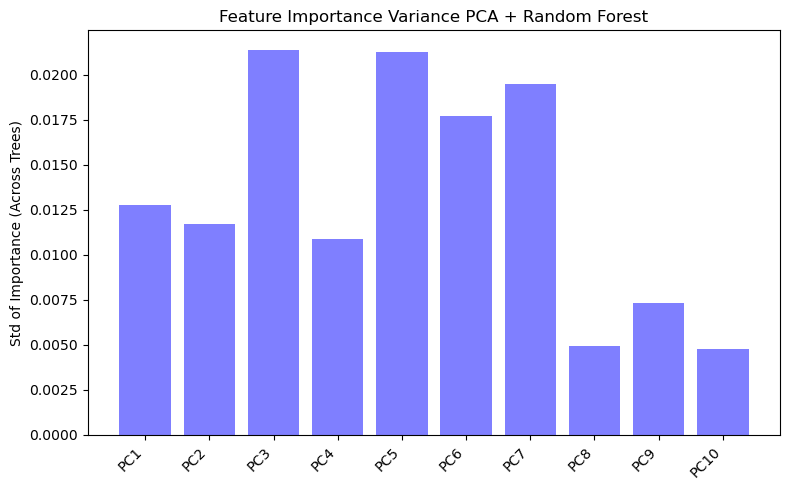

[INFO] - Average Variability: 0.01
[INFO] - Max Variability: 0.02


In [170]:
def feat_importance(model, feature_names, model_name):
    rf = model.named_steps['Model']

    # get importance from each tree
    tree_importance = np.array([estimator.feature_importances_ for estimator in rf.estimators_])
    avg_importance = tree_importance.mean(axis=0)
    std_importance = tree_importance.std(axis=0)

    # plot
    plt.figure(figsize = (8,5))
    
    plt.bar(range(len(avg_importance)), std_importance, color = 'blue', alpha = 0.5)
    plt.xticks(range(len(avg_importance)), feature_names, rotation = 45, ha = 'right')
    plt.title(f'Feature Importance Variance {model_name}')
    plt.ylabel('Std of Importance (Across Trees)')
    plt.tight_layout()
    plt.show()

    log(f'Average Variability: {np.mean(std_importance):.2f}', 'info')
    log(f'Max Variability: {np.max(std_importance):.2f}', 'info')


feat_importance(best_rf, feature_names = X_test.columns.tolist(), model_name = 'Random Forest')

pca = pca_rf.named_steps['PCA']
feat_importance(pca_rf,
                feature_names = [f'PC{i+1}' for i in range(pca.n_components_)] , 
                model_name = 'PCA + Random Forest'
                )

For Non-PCA RF:

- We see quite a number of features with high variance. This could indicate that trees disagree strongly on which feature matters most, or the features with the highest variance were used more, therefore a higher variance.

For PCA RF:

- We see lower variance across features as compared to Non-PCA model. Applying, PCA aids Random Forest in reducing the correlation between features. This is beneficial for the model as the trees do no fight for the correlated features to split on and the split becomes cleaner and mode stable. 

While PCA is usually not beneficial for Random Forest, in this specific case, we observed Random Forest benefitting more from PCA than without. PCA allowed Random Forest to increase the diversity between trees, which led to better splits, deeper trees, and better defined feature importance.

-----

### **f. Gradient Boosted Decision Trees**
-------

**XGBoost Gradient Boosted Decision Trees**

The default GDBT performs well on the dataset with ~94% accuracy. However, we want to explore if tuning the parameters of GDBT will increase the accuracy. Cross Validation on the Sciki-learn's GDBT will be really slow due to the time it takes to train a single GDBT model. 

We used XGBoost GDBT model instead as it allows:
- Faster approximation time using both the direction and curvature of the loss function
- Better overall predictions with best predicitons per leaf directly
- Prevents overfitting using L2 regularisation
- Introduce early stopping 

Overall better efficiency through cross validations

--------
Instead of Scikit's implementation of 1st order approximation where it only looks at the gradient of the loss function. XGBoost uses a 2nd order approximation approach. On top of looking at the gradient it also looks into the curvature of the loss.


$$
L(y_i, \hat{y}_i^{(t-1)} + f(x_i)) \approx L(y_i, \hat{y}_i^{(t-1)}) + g_i f(x_i) + \frac{1}{2} h_i f(x_i)^2
$$

where:

- Gradient (slope of the loss):  
  $$
  g_i = \frac{\partial L(y_i, \hat{y}_i^{(t-1)})}{\partial \hat{y}_i^{(t-1)}}
  $$

- Hessian (curvature of the loss):  
  $$
  h_i = \frac{\partial^2 L(y_i, \hat{y}_i^{(t-1)})}{\partial (\hat{y}_i^{(t-1)})^2}
  $$

XGBoost is able to estimate more than just the direction to move but also how big of a step to take.

---------------

XGBoost computes the optimal weight for each leaf node analytically:

$$
w_j^* = -\frac{\sum_{i \in I_j} g_i}{\sum_{i \in I_j} h_i + \lambda}
$$

and calculates the gain (improvement in loss) for each potential split:

$$
\text{Gain} = \frac{1}{2} \left[\frac{(\sum_{i \in I_L} g_i)^2}{\sum_{i \in I_L} h_i + \lambda} + \frac{(\sum_{i \in I_R} g_i)^2}{\sum_{i \in I_R} h_i + \lambda} - \frac{(\sum_{i \in I} g_i)^2}{\sum_{i \in I} h_i + \lambda}\right] - \gamma
$$

where:

- lambda is the L2 regularization term (controls leaf weight magnitude)
- gamma is the penalty for adding an extra leaf (controls tree complexity)

These characteristics of XGBoost allows it to:

- Choose splits that truly reduce loss
- Penalize overly complex trees
- Stop growing early when there’s little gain (pruning)

------

In [171]:
# dynamic function for xgboost cv to reproduce for pca as well
def train_xgb_cv(X_train, y_train, groups = train_df['block_id'], param_grid= None, use_pca = False):

    gkf = GroupKFold(n_splits = 5)
    param_combinations = list(ParameterGrid(param_grid)) # construct parameter search space

    xgb_best_score = -np.inf
    xgb_best_params = None
    xgb_best_m = None # store best performing model

    # loop through the parameter search space
    for params in param_combinations:
        fold_scores = []
        
        # loop through folds
        for fold, (train_idx, val_idx) in enumerate(
            tqdm(gkf.split(X_train, y_train, groups),
                total=gkf.get_n_splits(),
                leave=False, ncols=80) 
                ):

            X_tr, X_val = X_train.iloc[train_idx], X_train.iloc[val_idx]
            y_tr, y_val = y_train[train_idx], y_train[val_idx]

            if use_pca == True:
                # scaling required for pca
                scaler = StandardScaler()
                X_tr_scaled = scaler.fit_transform(X_tr)
                X_val_scaled = scaler.transform(X_val)

                pca = PCA(n_components=10)
                X_tr = pca.fit_transform(X_tr_scaled)
                X_val = pca.transform(X_val_scaled)

            # converting data to xgboost required format to bypass SKlearn API
            dtrain = xgb.DMatrix(X_tr, label = y_tr)
            dval = xgb.DMatrix(X_val, label = y_val)
            evals = [(dtrain, 'train'), (dval, 'eval')]

            params_core = {'objective': 'multi:softprob', # multiclass classification
                        'eval_metric': 'mlogloss',
                        'use_label_encoder': False,
                        'n_jobs': -1, 
                        'random_state': 101,
                        'num_class': 8,
                        **params  # parameter combinations
                        }

            # train on early stopping
            xgbooster = xgb.train(params = params_core,
                                dtrain=dtrain,
                                num_boost_round = 2000, # set max trees rounds to 2000
                                evals=evals,
                                early_stopping_rounds = 20, # stop if does not improve after 20 rounds
                                verbose_eval = False
            )
            
            # evaluate based on balanced accuracy score
            y_pred = np.argmax(xgbooster.predict(dval), axis =1)
            fold_score = balanced_accuracy_score(y_val, y_pred)
            fold_scores.append(fold_score)

            # mean score across folds
            mean_score = np.mean(fold_scores)

            # store best model
            if mean_score > xgb_best_score:
                xgb_best_score = mean_score
                xgb_best_params = params
                xgb_best_m = xgbooster

    log(f'\nBest parameter combination: {xgb_best_params}', 'info') 
    log(f'\nBest mean CV balanced accuracy: {xgb_best_score:.4f}', 'info')
    log(f'\nBest ntrees: {xgb_best_m.best_iteration}', 'info')

    return xgb_best_m, xgb_best_params, xgb_best_score

[INFO] - 
Best parameter combination: {'learning_rate': 0.05, 'max_depth': 7, 'subsample': 0.8}
[INFO] - 
Best mean CV balanced accuracy: 0.9595
[INFO] - 
Best ntrees: 337


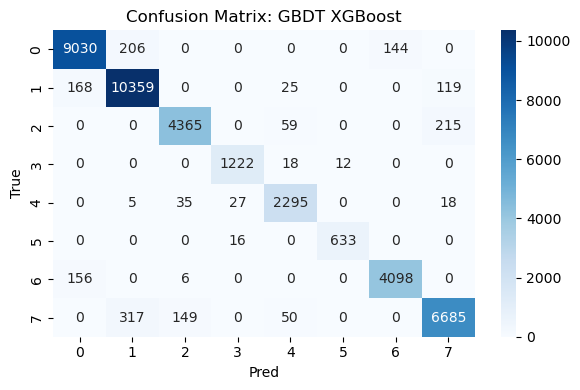

[INFO] - Classification Report:


,precision,recall,f1-score,support
alpine meadow,0.965362,0.962687,0.964023,9380.000000
alpine tundra,0.951502,0.970762,0.961035,10671.000000
bare rock,0.958288,0.940936,0.949532,4639.000000
dark rock,0.966008,0.976038,0.970997,1252.000000
scree/sunlit rock,0.937883,0.964286,0.950901,2380.000000
snow/ice,0.981395,0.975347,0.978362,649.000000
valley floor/meadow,0.966054,0.961972,0.964008,4260.000000
veg-scree mix,0.949979,0.928343,0.939036,7201.000000
,NaN,NaN,NaN,NaN
accuracy,0.956841,0.956841,0.956841,0.956841


[INFO] - Evaluation Metrics:


,Model,Error_Rate,Balanced_Accuracy,F1_score,AUC_score
0,GBDT XGBoost,0.043159,0.960046,0.956794,0.998929


In [172]:
param_grid = {
    'learning_rate': [0.05, 0.1, 0.3], 
    'max_depth': [3, 5, 7], # control tree complexity
    'subsample': [0.8, 1.0] # portion of the training rows used per tree
}

xgb_model, xgb_best_params, xgb_best_score = train_xgb_cv(X_train = X_train,
                                                          y_train = y_train,
                                                          param_grid = param_grid
)

xgboost_results = test(model_name = 'GBDT XGBoost',
                       model_fit = xgb_model,
                       X_test = X_test, 
                       y_test = y_test
                )

#### **PCA + Gradient Boosted Decision Tree (XGBoost)**

-----

[INFO] - 
Best parameter combination: {'learning_rate': 0.05, 'max_depth': 5, 'subsample': 0.8}
[INFO] - 
Best mean CV balanced accuracy: 0.9778
[INFO] - 
Best ntrees: 719


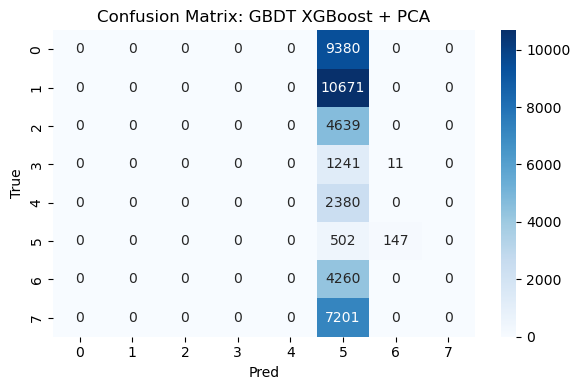

[INFO] - Classification Report:


,precision,recall,f1-score,support
alpine meadow,0.000000,0.000000,0.000000,9380.000000
alpine tundra,0.000000,0.000000,0.000000,10671.000000
bare rock,0.000000,0.000000,0.000000,4639.000000
dark rock,0.000000,0.000000,0.000000,1252.000000
scree/sunlit rock,0.000000,0.000000,0.000000,2380.000000
snow/ice,0.012465,0.773498,0.024534,649.000000
valley floor/meadow,0.000000,0.000000,0.000000,4260.000000
veg-scree mix,0.000000,0.000000,0.000000,7201.000000
,NaN,NaN,NaN,NaN
accuracy,0.012416,0.012416,0.012416,0.012416


[INFO] - Evaluation Metrics:


,Model,Error_Rate,Balanced_Accuracy,F1_score,AUC_score
0,GBDT XGBoost + PCA,0.987584,0.096687,0.000394,0.509317


In [173]:
pcaxgb_model, pcaxgb_best_params, pcaxgb_best_score = train_xgb_cv(X_train = pcaX_train,
                                                         y_train = y_train,
                                                          param_grid = param_grid,
                                                          use_pca = True
)

# pre-transform pca X_test as xgboost is not wrapped in scikit learn
pca_X_test_scaled = scaler.transform(pcaX_test)
pca_X_test = pca.transform(pca_X_test_scaled)

pca_xgboost_results = test(model_name = 'GBDT XGBoost + PCA',
                       model_fit = pcaxgb_model,
                       X_test = pca_X_test, 
                       y_test = y_test
                )

#### **PCA vs Non-PCA GBDT(XGBoost) Evaluation**

----

**Drop in XGBoost accuracy after applying PCA**

We used 4 main plots/statistics to explain the fall in accuracy after applying PCA to XGBoost

1. Tree Depth Distribution
2. Splits per Tree Distribution
3. Feature Importance (Gain metrics)
4. Tree Diversity (Std of Splits per Tree)

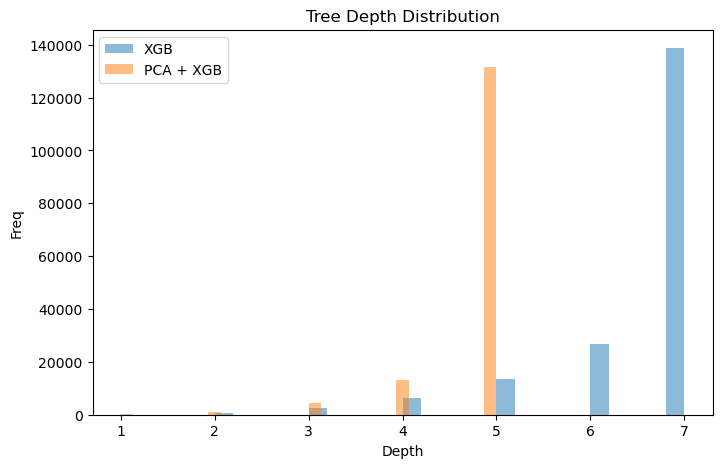

[INFO] - XGB Mean Depth: 6.54
[INFO] - PCA XGB Mean Depth: 4.82


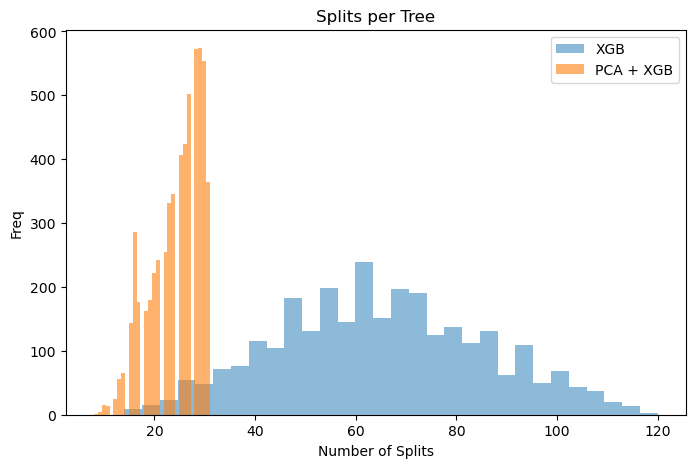

[INFO] - XGB Mean Splits per Tree: 64.92
[INFO] - PCA XGB Mean Splits per Tree: 24.45


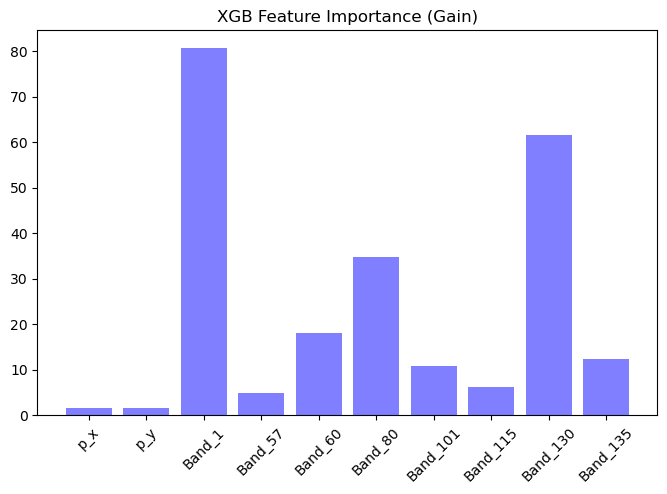

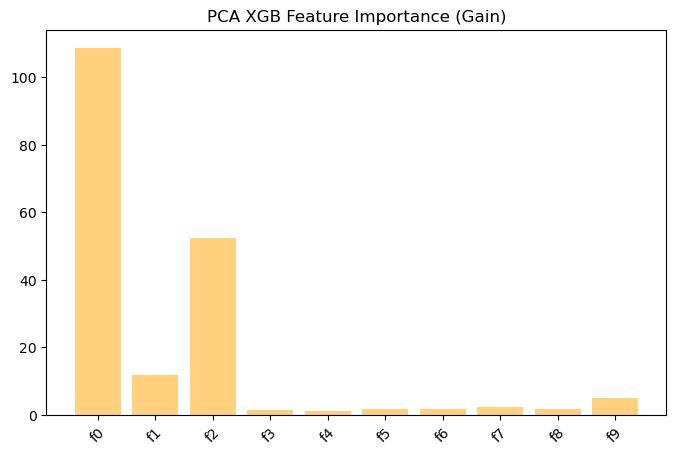

[INFO] - XGB Tree Diversity: 20.707
[INFO] - PCA XGB Tree Diversity: 4.964


In [174]:
# get tree info by walking through each node in XGB using depth first search
def extract_tree_info(model):
    # return a list of trees as a json strings
    trees = model.get_dump(dump_format = 'json')

    # store info
    depths = []
    n_splits = []
    gains = []

    # loop through each tree
    for tree in trees:
        tree = eval(tree) # convert json to dictionary

        # explore each tree using depth-first search 
        stack = [(tree, 0)] # each stack element is (node, depth); start with 0 depth 

        split_count = 0  # start count of decision nodes in tree

        # pop a single node off stack at a time
        while stack:
            node, depth = stack.pop()

            if 'split' in node:
                split_count += 1

                # each split node carrys a 'gain' value
                if 'gain' in node:
                    gains.append(node['gain'])
                
                # push children into stack with depth increase by 1, each split node has 2 children (allow to go through the entire tree)
                stack.append((node['children'][0], depth + 1))
                stack.append((node['children'][1], depth + 1))

            else:
                # node is a lead
                depths.append(depth)

        n_splits.append(split_count) # store splits in each tree

    # return distribution of depth, splits per tree, and gain values 
    return np.array(depths), np.array(n_splits), np.array(gains)

# get feature importance
def gainImportance(model):
    importance = model.get_score(importance_type = 'gain')

    return importance

# main function comparing non-pca xgboost with pca xgboost
def main(model, pca_model):

    depths, n_splits, gains = extract_tree_info(model)
    pca_depths, pca_n_splits, pca_gains = extract_tree_info(pca_model)

    # tree depth plot
    plt.figure(figsize = (8, 5))
    plt.hist(depths, bins = 30, alpha = 0.5, label = 'XGB')
    plt.hist(pca_depths, bins = 30, alpha = 0.5, label = 'PCA + XGB')

    # plot config
    plt.title('Tree Depth Distribution')
    plt.xlabel('Depth'); 
    plt.ylabel('Freq')

    plt.legend();
    plt.show()

    log(f'XGB Mean Depth: {depths.mean():.2f}', 'info')
    log(f'PCA XGB Mean Depth: {pca_depths.mean():.2f}', 'info')

    # split counts
    plt.figure(figsize = (8 ,5))
    plt.hist(n_splits, bins = 30, alpha = 0.5, label = 'XGB')
    plt.hist(pca_n_splits, bins = 30, alpha = 0.6, label = 'PCA + XGB')

    plt.title('Splits per Tree')
    plt.xlabel('Number of Splits');
    plt.ylabel('Freq')
    plt.legend();
    plt.show()

    log(f'XGB Mean Splits per Tree: {n_splits.mean():.2f}', 'info')
    log(f'PCA XGB Mean Splits per Tree: {pca_n_splits.mean():.2f}', 'info')

    # feature importance
    xgb_importance = gainImportance(model)
    pca_importance = gainImportance(pca_model)

    plt.figure(figsize = (8,5))
    plt.bar(xgb_importance.keys(), xgb_importance.values(), color = 'blue', alpha = 0.5)
    plt.title('XGB Feature Importance (Gain)')
    plt.xticks(rotation= 45)

    plt.figure(figsize=(8, 5))
    plt.bar(pca_importance.keys(), pca_importance.values(), color = 'orange', alpha = 0.5)
    plt.title('PCA XGB Feature Importance (Gain)')
    plt.xticks(rotation = 45)
    plt.show()

    # path diversity 
    xgb_diversity = np.std(n_splits)
    pca_diversity = np.std(pca_n_splits)

    log(f'XGB Tree Diversity: {xgb_diversity:.3f}', 'info')
    log(f'PCA XGB Tree Diversity: {pca_diversity:.3f}', 'info')


main(model=xgb_model, pca_model=pcaxgb_model)


From the plots, we see that although PCA is a dimensionality reduction technique, it is not beneficial for XGBoost. In the Tree Depth Distribution, the Non-PCA XGBoost model regularly grow trees to a depth of 7, while the PCA XGBoost model never exceeds depth 5. Indicating, PCA removes structural details that the tree would nomrally use to form deeper decision boundaries. We reinforced this using the Splits per Tree plot. Non-PCA XGboost averages around 65 splits per tree, whereas PCA model averages only 24 splits per tree. After PCA, it produces linear combinations of features, but XGBoost learns axis-aligned splits. Therefore, XGBoost struggles to find as many meaningful branching points from the blended features.

This effect is visible again in Feature Importance plot. Non-PCA XGBoost distributes importance across many meaningful features, while PCA XGBoost relies almost entirely on components 1 and 3. PCA blends many important variables into linear componenets, XGBoost loses the ability to isolate and interpret the original singals. Finally, Tree Diversity confirms this, PCA XGBoost show low diversity value, meaning each tree created are almost identical. Boosting works because each tree correct the mistakes of the previous, but with the compressed data of PCA, the trees become too similar and lose its corrective power.

-----

### **g. Support Vector Machines(SVM)**

<span style="color:red">**NOTE**: 
- <span style="color:red">**DO NOT RUN SVM CODE CHUNKS (takes ~ 4 Hrs)**

-------

[WARNING] - Applying scaling for model: SVC(probability=True)
[INFO] - PCA is toggled off
Fitting 5 folds for each of 12 candidates, totalling 60 fits
[INFO] - Best parameters: {'Model__C': 5, 'Model__class_weight': 'balanced', 'Model__gamma': 'scale', 'Model__kernel': 'rbf'}
[INFO] - Best CV balance score: 0.9604


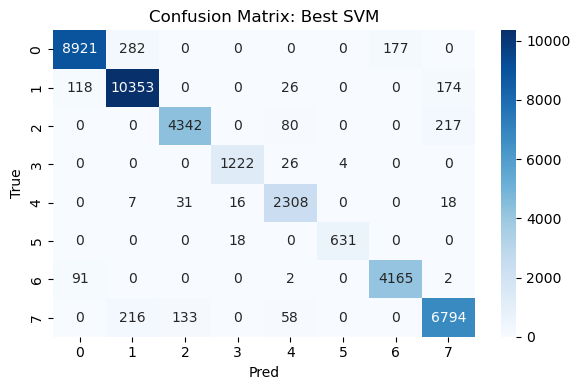

[INFO] - Classification Report:


,precision,recall,f1-score,support
alpine meadow,0.977108,0.951066,0.963911,9380.000000
alpine tundra,0.953491,0.970200,0.961772,10671.000000
bare rock,0.963604,0.935978,0.949590,4639.000000
dark rock,0.972930,0.976038,0.974482,1252.000000
scree/sunlit rock,0.923200,0.969748,0.945902,2380.000000
snow/ice,0.993701,0.972265,0.982866,649.000000
valley floor/meadow,0.959235,0.977700,0.968379,4260.000000
veg-scree mix,0.942956,0.943480,0.943218,7201.000000
,NaN,NaN,NaN,NaN
accuracy,0.958053,0.958053,0.958053,0.958053


[INFO] - Evaluation Metrics:


,Model,Error_Rate,Balanced_Accuracy,F1_score,AUC_score
0,Best SVM,0.041947,0.962059,0.95806,0.999051


In [175]:
svm_model_info = {
    'model': SVC(probability=True),
    'parameters':{
        'Model__kernel': ['rbf'],
        'Model__C' : [0.1, 1, 5],
        'Model__gamma': ['scale', 0.01, 0.1, 1],
        'Model__class_weight': ['balanced']
      }
    }


best_svm, best_param, best_score, gridscv_fit= train_cv(X_train=X_train, 
                                            y_train=y_train, 
                                            model_info = svm_model_info, 
                                            scale = True) 

best_svm_results = test(model_name = "Best SVM", 
                        model_fit = best_svm, 
                        X_test=X_test, 
                        y_test=y_test)


#### **PCA + SVM**

---

[WARNING] - Applying scaling for model: SVC(probability=True)
[INFO] - PCA is enabled
Fitting 5 folds for each of 12 candidates, totalling 60 fits
[INFO] - Best parameters: {'Model__C': 5, 'Model__class_weight': 'balanced', 'Model__gamma': 0.01, 'Model__kernel': 'rbf'}
[INFO] - Best CV balance score: 0.9910


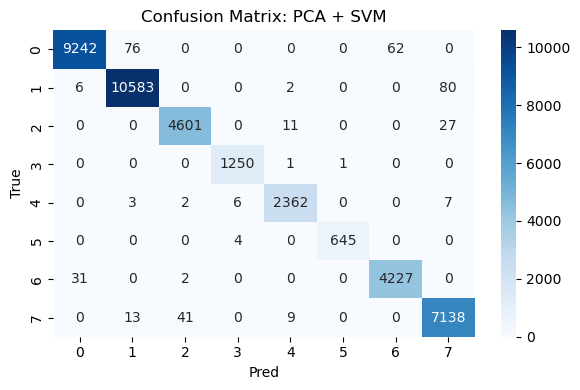

[INFO] - Classification Report:


,precision,recall,f1-score,support
alpine meadow,0.996013,0.985288,0.990621,9380.000000
alpine tundra,0.991382,0.991753,0.991568,10671.000000
bare rock,0.990314,0.991809,0.991061,4639.000000
dark rock,0.992063,0.998403,0.995223,1252.000000
scree/sunlit rock,0.990356,0.992437,0.991396,2380.000000
snow/ice,0.998452,0.993837,0.996139,649.000000
valley floor/meadow,0.985544,0.992254,0.988888,4260.000000
veg-scree mix,0.984280,0.991251,0.987753,7201.000000
,NaN,NaN,NaN,NaN
accuracy,0.990503,0.990503,0.990503,0.990503


[INFO] - Evaluation Metrics:


,Model,Error_Rate,Balanced_Accuracy,F1_score,AUC_score
0,PCA + SVM,0.009497,0.992129,0.990505,0.99996


In [176]:
pca_svm, pca_best_param, pca_best_score, pca_gridscv_fit = train_cv( X_train=pcaX_train,
                                                    y_train=y_train,
                                                    model_info = svm_model_info,
                                                    scale = True,
                                                    use_pca= True,
                                                    pca_ncomp=10
                                                )

pca_svm_results = test(model_name = "PCA + SVM",
                        model_fit = pca_svm,
                        X_test=pcaX_test,
                        y_test=y_test)

#### **PCA vs Non-PCA SVM Evaluation**

----

**1. Support Vector Count**

SVM relies exclusively on support vectors to construct its decision boundary. By analysing them, we can understand how PCA alters the geometric sturcture that SVM must learn.

In [177]:
suppvect = best_svm.named_steps['Model'].n_support_
suppvect_pca = pca_svm.named_steps['Model'].n_support_

suppvect_count = suppvect.sum()
pca_suppvect_count = suppvect_pca.sum()

log(f'Non-PCA SVM count: {suppvect_count}', 'info')
log(f'PCA SVM count: {pca_suppvect_count}', 'info')

[INFO] - Non-PCA SVM count: 20402
[INFO] - PCA SVM count: 11411


Non-PCA SVM:

- The model relies heavily on many support vectors, this forms more complex boundaries which leads to the model overfitting on dimensional noises.

PCA SVM:

- Dimensionality reduction technique from PCA, procuded a cleaner seperation feature space which enabled the SVM mnodel be less complex as it relies on fewer support vectors. This leads to model generalising better, as well as trains and predicts faster. Overall a better SVM model.

-----

**2. Margin Strength**

Margin quality reflects how confidently an SVM seperates the classes, based on how close the samples lie to the decision boundary. We measure this by examining the distribution of the SVM's decision fucntion values.

In a multiclass SVM one-vs-one classifier, for K classes there are:

$$ 
\frac{K(K-1)}{2} 
$$ 

pairwise classifiers. 

In our case we have *8x7/2 = 28* pairwise SVMs. The decision function returns 28 vectors for each samples. With element within the vector corresponds to the signed distance to the margin for one pair of classes. i.e. K_0 vs K_1, K_1 vs K_2, ... etc. 

The value of the element indicates the predicted class out of the pair. The magnitude of these values = Margin strength, which is how strongly does the model thinks it is class K.

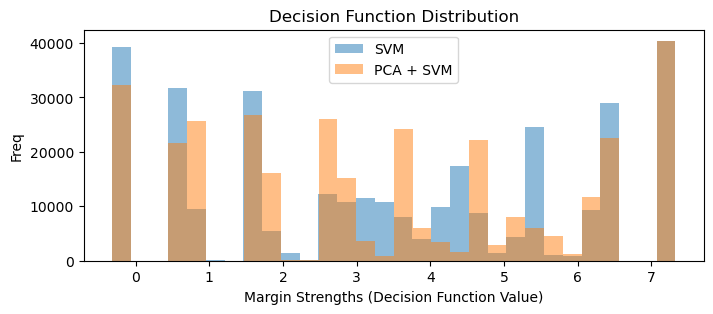

In [178]:
decision_func = best_svm.decision_function(X_test)

pca_decision_func = pca_svm.decision_function(pcaX_test)

plt.figure(figsize = (8, 3))

plt.hist(decision_func.ravel(), bins = 30, alpha = 0.5, label = 'SVM')
plt.hist(pca_decision_func.ravel(), bins = 30, alpha = 0.5, label = 'PCA + SVM')

plt.title('Decision Function Distribution')
plt.xlabel('Margin Strengths (Decision Function Value)')
plt.ylabel('Freq')
plt.legend()
plt.show()

We can split the Decision Function Distribution into 3 sections:
1. Margin strength of 0 and 1: Weak margin, model is not confident 
2. Margin strength of 3 to 5: Model has medium confidence in its classifications
3. Margin strength of 7: Strong margin, model is very confident with its predictions.

Non-PCA SVM:

- Non-PCA SVM has a larger concertation of margin values close to 0, which means many test samples lie very close to the decision boundaries. This indicates weak seperability and a complex and noisy decision surface. This is inline with the previous statistics of Non-PCA SVM relying on more number of support vectors as it struggles to form confident boundaries.

PCA-SVM:

- The model exhibits fewer near 0 margins and more frequents medium to high margin values. PCA's reshaping of the feature space makes the classes more cleanly seperable, leading to simpler and stronger decision boundaries that relies on fewer support vectors.

This explains the higher accuracy of PCA + SVM model than the base SVM.

------

## **5. Glacier Dectection**

____

### **Data Preparation**

Assigning:

- 1 = glacier (snow/ice)
- 0 = all other land types.

----

In [179]:
test_blocks_glacier = ['2_1', '3_1', '0_2'] # test block_ids

test_df_glacier = (bcluster_df[bcluster_df['block_id'].isin(test_blocks_glacier)].copy()) # test data
train_df_glacier = (bcluster_df[~bcluster_df['block_id'].isin(test_blocks_glacier)].copy()) # train data

train_df_glacier['glacier'] = (train_df_glacier['land_type'] == 'snow / ice').astype(int)
test_df_glacier['glacier'] = (test_df_glacier['land_type'] == 'snow / ice').astype(int)

X_train_glacier = train_df_glacier.drop(columns=['land_type', 'block_x', 'block_y', 'block_id', 'glacier'])
y_train_glacier = train_df_glacier['glacier']

X_test_glacier = test_df_glacier.drop(columns=['land_type', 'block_x', 'block_y', 'block_id', 'glacier'])
y_test_glacier = test_df_glacier['glacier']

### **Classification Models**

-----

##### **Modelling Helper Functions**

In [180]:
def gtrain_stratified(X_train, y_train, model_info, groups = train_df_glacier['block_id'], scale = False):

    model = model_info['model']
    param_grid = model_info['parameters']
    steps = []

    if scale == True:
        steps.append(('Scaler', StandardScaler()))

    steps.append(('Model', model))
    pipeline = Pipeline(steps)

    sgkf = StratifiedGroupKFold(n_splits = 5)

    CV = GridSearchCV(estimator = pipeline,
                      param_grid = param_grid,
                      cv = sgkf,
                      n_jobs = -1,
                      scoring = 'balanced_accuracy'
                    )

    CV.fit(X_train, y_train, groups = groups)

    best_model = CV.best_estimator_
    best_params = CV.best_params_
    best_score = CV.best_score_

    log(f'Best parameters: {best_params}', 'info')
    log(f'Best CV balance score: {best_score:.4f}', 'info')

    return best_model, best_params, best_score, CV

In [181]:
def gtest_binary(model_name, model_fit, X_test, y_test):
    y_pred = model_fit.predict(X_test)

    if hasattr(model_fit, 'predict_proba'):
        y_pred_proba = model_fit.predict_proba(X_test)

    else:
        y_pred_proba = None

    # plot confusion matrix
    conf_matrix = confusion_matrix(y_test, y_pred)

    plt.figure(figsize=(6,4))
    sns.heatmap(conf_matrix, annot= True, fmt = 'd', cmap = 'Blues',
                xticklabels = ['Non-Glacier', 'Glacier'], 
                yticklabels = ['Non-Glacier', 'Glacier']
                )

    plt.title(f'Confusiojn Matrix: {model_name}')
    plt.xlabel('Predicted') 
    plt.ylabel('True')
    plt.tight_layout()
    plt.show()

    # error rate 
    error_rate = 1 - (np.trace(conf_matrix)/np.sum(conf_matrix))

    # balanced accuracy
    balanced = balanced_accuracy_score(y_test, y_pred)

    # f1 score
    f1 = f1_score(y_test, y_pred, average = 'binary')

    if y_pred_proba is not None:
        auc_score = roc_auc_score(y_test, y_pred_proba[:, 1])

    else:
        auc_score = np.nan

    cf = classification_report(y_test, y_pred,
                                target_names = ['Non-Glacier', 'Glacier'],
                                output_dict = True)
    
    class_reportdf = pd.DataFrame(cf).T
    
    if 'accuracy' in class_reportdf.index:
        indx = class_reportdf.index.get_loc('accuracy')
        empty_row = pd.Series(name = ' ')
        class_reportdf = pd.concat(
            [class_reportdf.iloc[:indx], pd.DataFrame([empty_row]), class_reportdf.iloc[indx:]]
            )
        
    log('Classification Report:', 'info')
    display(class_reportdf)

    results_dict = {
        'Model': model_name,
        'Error_Rate': error_rate,
        'Balanced_Accuracy': balanced,
        'F1_score': f1,
        'AUC_score': auc_score
    }

    log('Evaluation Metrics', 'info')
    display(pd.DataFrame([results_dict]))
    
    return results_dict, cf


### **Model 1: Logistic Regression**
---

[INFO] - Best parameters: {'Model__C': 1.0, 'Model__class_weight': 'balanced', 'Model__penalty': 'l1', 'Model__solver': 'saga'}
[INFO] - Best CV balance score: 0.9986


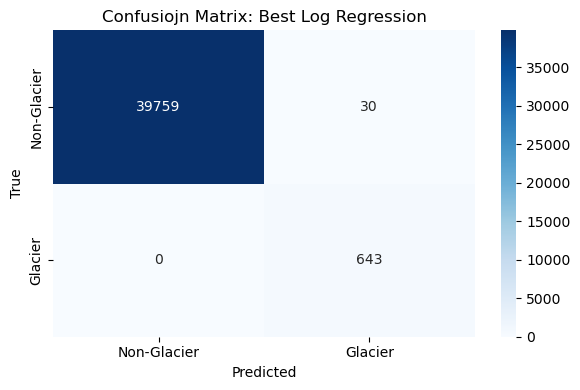

[INFO] - Classification Report:


,precision,recall,f1-score,support
Non-Glacier,1.000000,0.999246,0.999623,39789.000000
Glacier,0.955423,1.000000,0.977204,643.000000
,NaN,NaN,NaN,NaN
accuracy,0.999258,0.999258,0.999258,0.999258
macro avg,0.977712,0.999623,0.988413,40432.000000
weighted avg,0.999291,0.999258,0.999266,40432.000000


[INFO] - Evaluation Metrics


,Model,Error_Rate,Balanced_Accuracy,F1_score,AUC_score
0,Best Log Regression,0.000742,0.999623,0.977204,0.999993


In [182]:
glog_model_info = {
    'model': LogisticRegression(max_iter=5000),
    'parameters': [
        {
        'Model__penalty': ['l1','l2'],
        'Model__C': [0.1,0.5,1.0],
        'Model__solver': ['saga'],
        'Model__class_weight': ['balanced']
    },
    
    # seperate grid search for elastic net to specify l1 ratio
    {
        'Model__penalty': ['elasticnet'],
        'Model__C': [0.1, 0.5, 1.0],
        'Model__solver': ['saga'],
        'Model__l1_ratio': [0.2, 0.5, 0.8], # 0 = using L2, 1 = using L1
        'Model__class_weight': ['balanced']
    }
    ]
}

best_logreg_g, best_param, best_score, glog_CV = gtrain_stratified(X_train=X_train_glacier, 
                                                                                y_train=y_train_glacier, 
                                                                                model_info = glog_model_info,
                                                                                scale = True
                                                                                ) 

g_logreg_results = gtest_binary(model_name = "Best Log Regression",
                        model_fit = best_logreg_g, 
                        X_test=X_test_glacier, 
                        y_test=y_test_glacier)


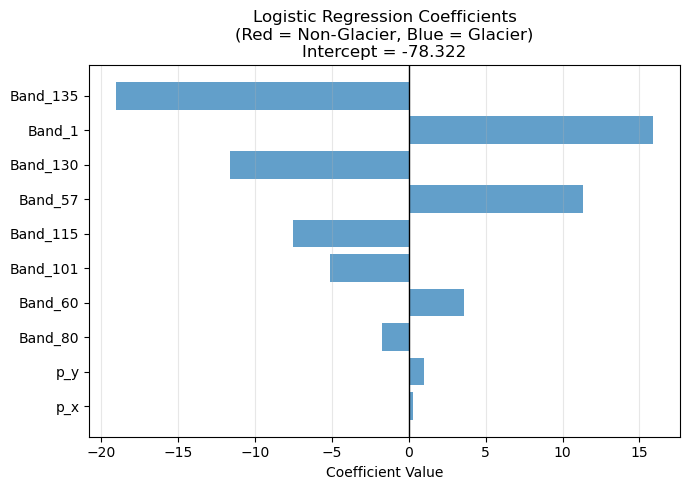

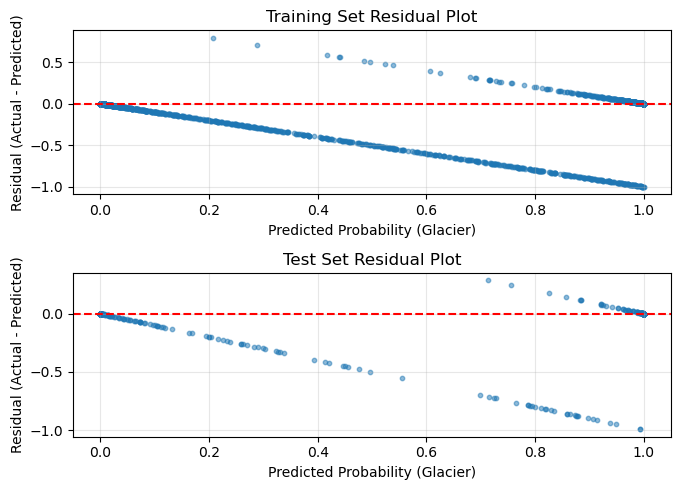

In [183]:
def coefficients_plot(model, X_test):
    estimator = model.named_steps['Model']

    coef = estimator.coef_.flatten()
    intercept = estimator.intercept_[0]

    feature_names = X_test.columns.tolist()

    # Sort top 20 by absolute value
    sorted_indx = np.argsort(np.abs(coef))[::-1]
    top_n = min(20, len(coef))
    top_indx = sorted_indx[:top_n]

    fig, ax = plt.subplots(figsize=(7, 5))

    ax.barh(range(top_n), 
            coef[top_indx], 
            color="tab:blue", 
            alpha=0.7)
    
    ax.set_yticks(range(top_n))
    ax.set_yticklabels([feature_names[i] for i in top_indx])
    ax.set_xlabel("Coefficient Value")
    ax.set_title(f"Logistic Regression Coefficients\n"
                 f"(Red = Non-Glacier, Blue = Glacier)\nIntercept = {intercept:.3f}")
    
    ax.axvline(x=0, color='black', linewidth=1)
    ax.invert_yaxis()
    ax.grid(True, alpha=0.3, axis='x')
    plt.tight_layout()
    plt.show()


def residuals_plot(model, X_train, y_train, X_test, y_test):

    y_pred_proba_train = model.predict_proba(X_train)[:, 1]
    y_pred_proba_test = model.predict_proba(X_test)[:, 1]

    # residuals = actual - predicted prob
    residuals_train = y_train - y_pred_proba_train
    residuals_test = y_test - y_pred_proba_test

    fig, axes = plt.subplots(2, 1, figsize=(7, 5))

    # train residuals
    axes[0].scatter(y_pred_proba_train, residuals_train, alpha=0.5, s=10)
    axes[0].axhline(y=0, color='red', linestyle='--')
    axes[0].set_xlabel("Predicted Probability (Glacier)")
    axes[0].set_ylabel("Residual (Actual - Predicted)")
    axes[0].set_title("Training Set Residual Plot")
    axes[0].grid(True, alpha=0.3)

    # test residuals
    axes[1].scatter(y_pred_proba_test, residuals_test, alpha=0.5, s=10)
    axes[1].axhline(y=0, color='red', linestyle='--')
    axes[1].set_xlabel("Predicted Probability (Glacier)")
    axes[1].set_ylabel("Residual (Actual - Predicted)")
    axes[1].set_title("Test Set Residual Plot")
    axes[1].grid(True, alpha=0.3)

    plt.tight_layout()
    plt.show()

coefficients_plot(best_logreg_g, X_test_glacier)
residuals_plot(best_logreg_g, X_train_glacier, y_train_glacier, X_test_glacier, y_test_glacier)

### **Model 2: Tree Fed Logisitic Regression**

----

In [ ]:
class RFFedLogistic:
    def __init__(self,
                 rf_params=None,
                 logreg_grid=None,
                 cv_splits=5,
                 random_state=42):

        # search grid for rf
        rf_params = {"n_estimators": 50,
                    "max_depth": 8,
                    "n_jobs": -1,
                    "random_state": random_state
                    }

        self.rf = RandomForestClassifier(**rf_params)

        # search grid for logistic regression
        logreg_grid = {
            'model': LogisticRegression(max_iter=5000),
            'parameters': [
                {
                    'Model__penalty': ['l1','l2'],
                    'Model__C': [0.1, 0.5, 1.0],
                    'Model__solver': ['saga'],
                    'Model__class_weight': ['balanced']
                },
                {
                    'Model__penalty': ['elasticnet'],
                    'Model__C': [0.1, 0.5, 1.0],
                    'Model__solver': ['saga'],
                    'Model__l1_ratio': [0.2,0.5,0.8],
                    'Model__class_weight': ['balanced']
                }
            ]
        }
        # store parameters
        self.logreg_grid = logreg_grid
        self.cv_splits = cv_splits
        self.random_state = random_state

        # placeholders
        self.best_logreg = None
        self.groups = None

    # fit method
    def fit(self, X, y, groups=train_df_glacier['block_id']):
        self.groups = groups

        log("Training Random Forest", "info")
        self.rf.fit(X, y)

        X_rf = self.rf.predict_proba(X)

        log("Feeding RF Output into Logistic Regression", "info")

        pipeline = Pipeline([
            ('Scaler', StandardScaler()),
            ('Model', LogisticRegression(max_iter=2000))
        ])

        cv = StratifiedGroupKFold(
            n_splits=self.cv_splits,
            shuffle=True,
            random_state=self.random_state
        )

        grid = GridSearchCV(
            estimator=pipeline,
            param_grid=self.logreg_grid['parameters'],
            scoring='balanced_accuracy',
            cv=cv,
            n_jobs=-1
        )
    
        grid.fit(X_rf, y, groups=groups)

        # store best logistic regression
        self.best_logreg = grid.best_estimator_
        self.best_params = grid.best_params_
        self.cv_score = grid.best_score_
        self.cv_results = grid.cv_results_

        log(f"Best Logistic Regression params: {self.best_params}", "info")
        log(f"Best CV Balanced Accuracy: {self.cv_score:.4f}", "info")

        return self

    def predict(self, X):
        X_rf = self.rf.predict_proba(X)
        return self.best_logreg.predict(X_rf)

    def predict_proba(self, X):
        X_rf = self.rf.predict_proba(X)
        return self.best_logreg.predict_proba(X_rf)

[INFO] - Training Random Forest
[INFO] - Feeding RF Output into Logistic Regression
[INFO] - Best Logistic Regression params: {'Model__C': 0.1, 'Model__class_weight': 'balanced', 'Model__penalty': 'l1', 'Model__solver': 'saga'}
[INFO] - Best CV Balanced Accuracy: 0.9989


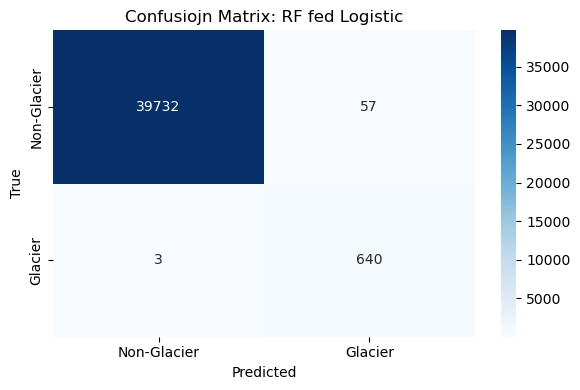

[INFO] - Classification Report:


,precision,recall,f1-score,support
Non-Glacier,0.999924,0.998567,0.999246,39789.000000
Glacier,0.918221,0.995334,0.955224,643.000000
,NaN,NaN,NaN,NaN
accuracy,0.998516,0.998516,0.998516,0.998516
macro avg,0.959073,0.996951,0.977235,40432.000000
weighted avg,0.998625,0.998516,0.998545,40432.000000


[INFO] - Evaluation Metrics


,Model,Error_Rate,Balanced_Accuracy,F1_score,AUC_score
0,RF fed Logistic,0.001484,0.996951,0.955224,0.999969


In [185]:
model = RFFedLogistic()

model.fit(X_train_glacier,
            y_train_glacier
            )

treefed_log_results = gtest_binary(model_name="RF fed Logistic",
                                    model_fit=model,
                                    X_test=X_test_glacier,
                                    y_test=y_test_glacier
                                )

In [186]:
def rfflogreg_coefficients(model, title_suffix=""):

    final_estimator = model.named_steps['Model']
    coef = final_estimator.coef_.flatten()
    intercept = final_estimator.intercept_[0]

    # names of RF probability features
    feature_names = ['RF Prob (Non-Glacier)', 'RF Prob (Glacier)']
    colors = ['red' if c < 0 else 'blue' for c in coef]

    fig, ax = plt.subplots(figsize=(8, 5))
    bars = ax.bar(feature_names, coef, color=colors, alpha=0.7, edgecolor='black')

    ax.axhline(y=0, color='black', linewidth=0.8)
    ax.set_ylabel('Coefficient Value')
    ax.set_title(f'Logistic Regression Coefficients {title_suffix}\nIntercept: {intercept:.3f}')
    ax.grid(True, alpha=0.3, axis='y')

    # Add numeric labels
    for bar in bars:
        height = bar.get_height()
        ax.text(
            bar.get_x() + bar.get_width() / 2., height,
            f'{height:.3f}', ha='center',
            va='bottom' if height > 0 else 'top'
        )

    plt.tight_layout()
    plt.show()


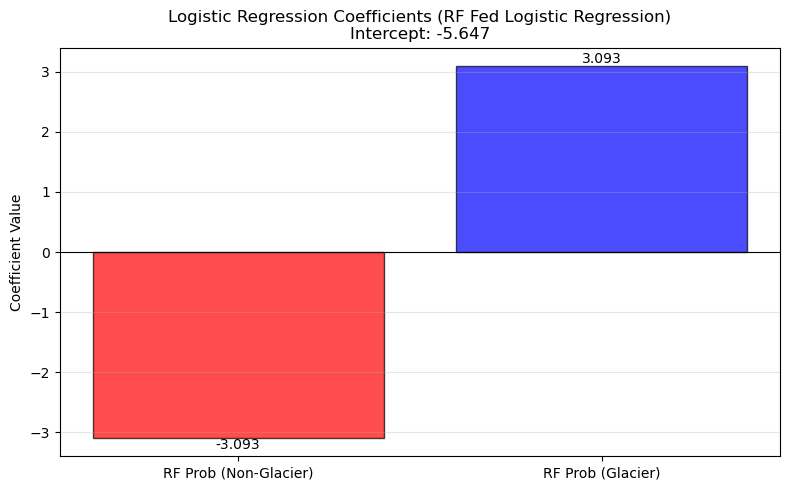

In [187]:
rfflogreg_coefficients(model = model.best_logreg, title_suffix="(RF Fed Logistic Regression)")

### **Model 3: KNN**

-----

[INFO] - Best parameters: {'Model__metric': 'manhattan', 'Model__n_neighbors': 7, 'Model__weights': 'distance'}
[INFO] - Best CV balance score: 0.9896


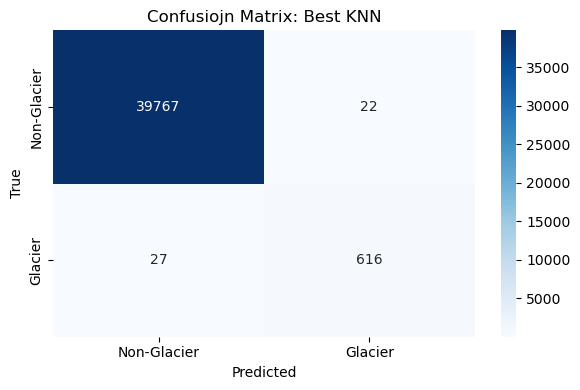

[INFO] - Classification Report:


,precision,recall,f1-score,support
Non-Glacier,0.999322,0.999447,0.999384,39789.000000
Glacier,0.965517,0.958009,0.961749,643.000000
,NaN,NaN,NaN,NaN
accuracy,0.998788,0.998788,0.998788,0.998788
macro avg,0.982419,0.978728,0.980566,40432.000000
weighted avg,0.998784,0.998788,0.998786,40432.000000


[INFO] - Evaluation Metrics


,Model,Error_Rate,Balanced_Accuracy,F1_score,AUC_score
0,Best KNN,0.001212,0.978728,0.961749,0.998352


In [188]:
g_knn_model_info = {
    'model': KNeighborsClassifier(),
    'parameters': {
    'Model__n_neighbors': [3, 5, 7, 9, 11, 15, 20],
    'Model__weights': ['uniform', 'distance'],
    'Model__metric': ['euclidean', 'manhattan']
    }
}

best_gknn, best_param, best_score, gknn_CV = gtrain_stratified(X_train=X_train_glacier, 
                                                                            y_train=y_train_glacier, 
                                                                            model_info = g_knn_model_info,
                                                                            scale = True
                                                                            ) 

g_knn_results = gtest_binary(model_name = "Best KNN",
                                model_fit = best_gknn, 
                                X_test=X_test_glacier, 
                                y_test=y_test_glacier)

In [189]:
def k_weights(results_df):

    fig, ax = plt.subplots(figsize=(7, 5))

    for weight in ['uniform', 'distance']:
        mask = results_df['param_Model__weights'] == weight
        k_scores = (results_df[mask]
                    .groupby('param_Model__n_neighbors')['mean_test_score']
                    .mean()
                    .sort_index())
        ax.plot(k_scores.index, k_scores.values,
                marker='o', linewidth=2, markersize=8, label=weight)

    ax.set_xlabel('Number of Neighbors (K)')
    ax.set_ylabel('Mean CV Balanced Accuracy')
    ax.set_title('KNN Performance vs K (by Weight Type)')
    ax.grid(True, alpha=0.3)
    ax.legend()
    ax.set_xticks(sorted(results_df['param_Model__n_neighbors'].unique()))

    plt.tight_layout()
    plt.show()

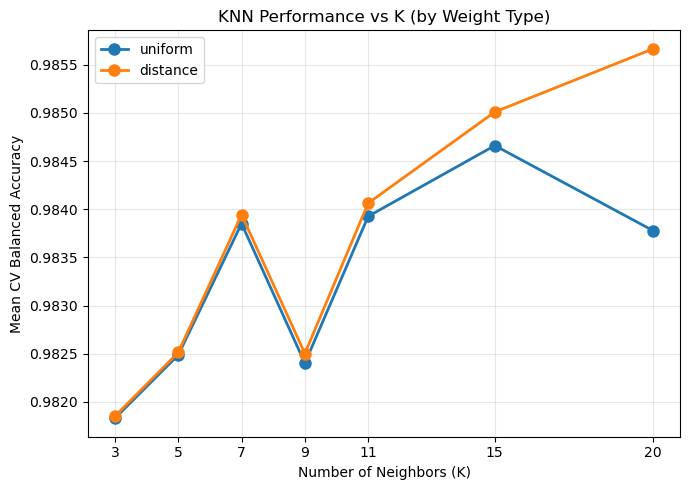

In [190]:
results_df = pd.DataFrame(gknn_CV.cv_results_)
k_weights(results_df)

## **6. mypredict()** function

----

In [ ]:
def mypredict():    
    '''
    -  Reads from text.csv.gz from current working directory.
    -  Preprocess the data by creating spatial blocks and dropping unnecessary columns
    -  Applies PCA + SVM model to make predictions
    -  Write predictions to 'prediction.txt' in current working directory
    -  Returns the output file path
    '''

    # test data passed in
    test_path = "test.csv.gz"
    test_df = pd.read_csv(test_path)


    # preprocess test data to use p_x and p_y to create spatial blocks
    blockTest_df, unique_blocks = create_blocks(test_df)
    cols_to_drop = ['block_x', 'block_y', 'block_id'] # drop columns

    # check if unnecessary columns exist, if it does drop them
    if 'rgb_hex' in blockTest_df.columns:
        cols_to_drop.append('rgb_hex')
    if 'overlay_hex' in blockTest_df.columns:
        cols_to_drop.append('overlay_hex')
    if 'land_type' in blockTest_df.columns:
        cols_to_drop.append('land_type')

    X_test = blockTest_df.drop(columns=cols_to_drop)    

    model_fit = pca_svm
    y_pred = model_fit.predict(X_test)
    y_pred = np.asarray(y_pred).ravel().astype(int) # flatten to 1D array

    label_mapping = {
    'alpine meadow': 0,
    'alpine tundra': 1,
    'bare rock': 2,
    'dark rock': 3,
    'sunlit rock': 4,
    'snow': 5,
    'valley floor': 6,
    'veg-scree mix': 7
        }

    reverse_mapping = {v: k for k, v in label_mapping.items()}
    
    #  map encoded numbers back to original labels
    y_pred_labels = [reverse_mapping[c] for c in y_pred]

    # write predictions to txt file
    output_path = "predictions.txt"
    with open(output_path, 'w') as f:
        for label in y_pred_labels:
            f.write(str(label) + "\n")

    return output_path

mypredict()